<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 12px; padding: 20px; text-align: center;'>
    <font size="+3" color="#e94560"><b>🌿 Cotton Leaf Disease Detection 🌿</b></font><br>
    <font size="+1" color="#0f3460"><b>Multi-Model Comparison: ResNet50 | EfficientNet-B0 | MobileNetV3 | DenseNet121</b></font>
</div>
<div style='background-color: #f0fff0; border: 4px solid #32CD32; border-radius: 12px; padding: 10px; text-align: center; margin-top: 10px;'>
    <font size="+1" color="#32CD32"><b>📊 Systematic Evaluation of Lightweight CNN Architectures for Offline Crop Disease Diagnosis</b></font>
</div>

<div style='background-color: #e6f7ff; border: 3px solid #0078FF; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#0078FF"><b>🛠️ 1. Custom Datasets & DataLoaders 🛠️</b></font>
</div>

In [1]:
import os
import torch
import numpy as np
from glob import glob
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

torch.manual_seed(2025)

def find_dataset_root(candidate_root):
    """
    Checks if candidate_root exists and contains image files.
    If not, automatically searches /kaggle/input for the cotton leaf dataset directory.
    """
    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.JPG', '.JPEG', '.PNG')
    
    # 1. Check direct candidate path
    if os.path.exists(candidate_root):
        for root_dir, _, files in os.walk(candidate_root):
            if any(f.endswith(valid_exts) for f in files):
                return candidate_root
                
    # 2. Search dynamically in /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        print(f"Candidate root not found. Auto-scanning '{kaggle_input}' for dataset...")
        # Check all immediate subfolders in kaggle input
        for sub in os.listdir(kaggle_input):
            sub_path = os.path.join(kaggle_input, sub)
            for root_dir, dirs, files in os.walk(sub_path):
                img_files = [f for f in files if f.endswith(valid_exts)]
                if len(img_files) > 10:
                    parent = os.path.dirname(root_dir)
                    print(f"Auto-detected dataset root at: {parent}")
                    return parent
                    
    return candidate_root

class CustomDataset(Dataset):
    def __init__(self, root, transformations=None, im_paths=None, im_lbls=None, im_files=[".png", ".jpg", ".jpeg", ".bmp", ".JPG", ".JPEG", ".PNG"], use_albumentations=False):
        
        self.transformations = transformations
        self.use_albumentations = use_albumentations
        
        if im_paths is not None and im_lbls is not None:
            self.im_paths = im_paths
            self.im_lbls = im_lbls        
        else:
            # Recursive scan to avoid depth/nesting issues
            valid_exts = tuple(im_files)
            found_paths = []
            for root_dir, _, files in os.walk(root):
                for file in files:
                    if file.endswith(valid_exts):
                        found_paths.append(os.path.normpath(os.path.join(root_dir, file)))
            
            self.im_paths = sorted(found_paths)
            
            if len(self.im_paths) == 0:
                available = os.listdir("/kaggle/input") if os.path.exists("/kaggle/input") else "None"
                raise ValueError(
                    f"No images found in root: '{root}'.\n"
                    f"Please check the dataset folder in Kaggle. Contents of /kaggle/input: {available}"
                )
            
            print(f"Discovered {len(self.im_paths)} images across categories.")
        
        self.cls_names, self.cls_counts = {}, {}
        count = 0
        for im_path in self.im_paths:
            class_name = self.get_class(im_path)
            if class_name not in self.cls_names:
                self.cls_names[class_name] = count
                self.cls_counts[class_name] = 1
                count += 1
            else:
                self.cls_counts[class_name] += 1        

    def get_class(self, path):
        # Platform-independent class extraction from parent folder
        return os.path.basename(os.path.dirname(os.path.normpath(path)))

    def __len__(self): return len(self.im_paths)

    def __getitem__(self, idx):
        im_path = self.im_paths[idx]
        im = Image.open(im_path).convert("RGB")        
        gt = self.im_lbls[idx]

        if self.transformations is not None:
            if self.use_albumentations:
                # Albumentations expects numpy array (H, W, C)
                im_np = np.array(im)
                augmented = self.transformations(image=im_np)
                im = augmented["image"]  # Returns torch.Tensor via ToTensorV2
            else:
                # Standard torchvision transforms
                im = self.transformations(im)

        return im, gt

    @classmethod
    def stratified_split_dls(cls, root, transformations, bs=8, split=[0.8, 0.1, 0.1], ns=4, 
                             train_transformations=None, use_albumentations_train=False):
        """
        Create stratified train/val/test DataLoaders.
        
        Args:
            root: Dataset root directory
            transformations: Default transforms (used for val/test, and train if train_transformations is None)
            bs: Batch size
            split: Train/val/test split ratios
            ns: Number of workers
            train_transformations: Optional separate transforms for training (e.g., Albumentations pipeline)
            use_albumentations_train: If True, training dataset uses Albumentations-compatible __getitem__
        """
        dataset = cls(root=root, transformations=transformations)
        
        im_paths = dataset.im_paths
        labels   = [dataset.cls_names[dataset.get_class(p)] for p in im_paths]        
        
        train_paths, temp_paths, train_lbls, temp_lbls = train_test_split(
            im_paths, labels, test_size=(split[1] + split[2]), stratify=labels, random_state=2025
        )

        # Second split: val and test
        val_ratio = split[1] / (split[1] + split[2])
        val_paths, test_paths, val_lbls, test_lbls = train_test_split(
            temp_paths, temp_lbls, test_size=(1 - val_ratio), stratify=temp_lbls, random_state=2025
        )

        # Use separate augmentation transforms for training if provided
        actual_train_tfs = train_transformations if train_transformations is not None else transformations
        
        train_ds = cls(root=root, transformations=actual_train_tfs, im_paths=train_paths, im_lbls=train_lbls,
                       use_albumentations=use_albumentations_train)
        val_ds = cls(root=root, transformations=transformations, im_paths=val_paths, im_lbls=val_lbls)
        test_ds = cls(root=root, transformations=transformations, im_paths=test_paths, im_lbls=test_lbls)
        
        train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True, num_workers=ns)
        val_dl = DataLoader(val_ds, batch_size=bs, shuffle=False, num_workers=ns)
        test_dl = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=ns)

        return train_dl, val_dl, test_dl, dataset.cls_names, [train_ds.cls_counts, val_ds.cls_counts, test_ds.cls_counts]

# Auto-locate dataset path
default_root = "/kaggle/input/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset"
root = find_dataset_root(default_root)
print(f"Using dataset root: {root}")

mean, std, im_size, bs = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225], 224, 16
tfs = T.Compose([T.Resize((im_size, im_size)), T.ToTensor(), T.Normalize(mean=mean, std=std)])

tr_dl, val_dl, ts_dl, classes, cls_counts = CustomDataset.stratified_split_dls(root=root, transformations=tfs, bs=bs)

print(f"Train batches: {len(tr_dl)} | Val batches: {len(val_dl)} | Test batches: {len(ts_dl)}")
print(f"Classes: {classes}")


Candidate root not found. Auto-scanning '/kaggle/input' for dataset...
Auto-detected dataset root at: /kaggle/input/datasets/sabuktagin/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset
Using dataset root: /kaggle/input/datasets/sabuktagin/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset
Discovered 2137 images across categories.
Train batches: 107 | Val batches: 14 | Test batches: 214
Classes: {'Bacterial Blight': 0, 'Curl Virus': 1, 'Healthy Leaf': 2, 'Herbicide Growth Damage': 3, 'Leaf Hopper Jassids': 4, 'Leaf Redding': 5, 'Leaf Variegation': 6}


<div style='background-color: #ffe6f2; border: 3px solid #ff1493; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#ff1493"><b>📊 2. Data Analysis 📊</b></font>
</div>

Data analysis is in process...

Data analysis is in process...

Data analysis is in process...



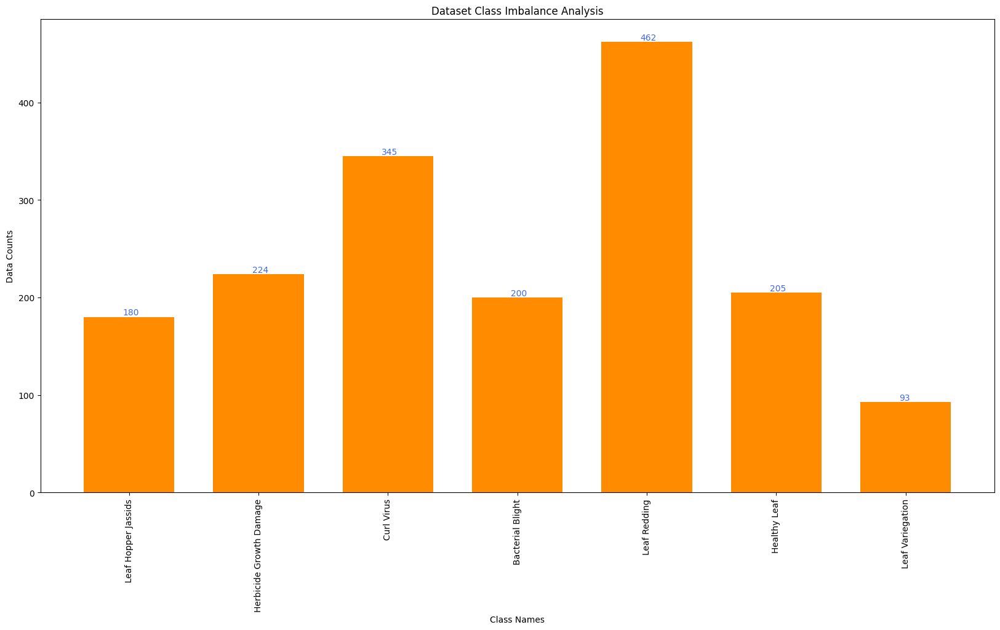

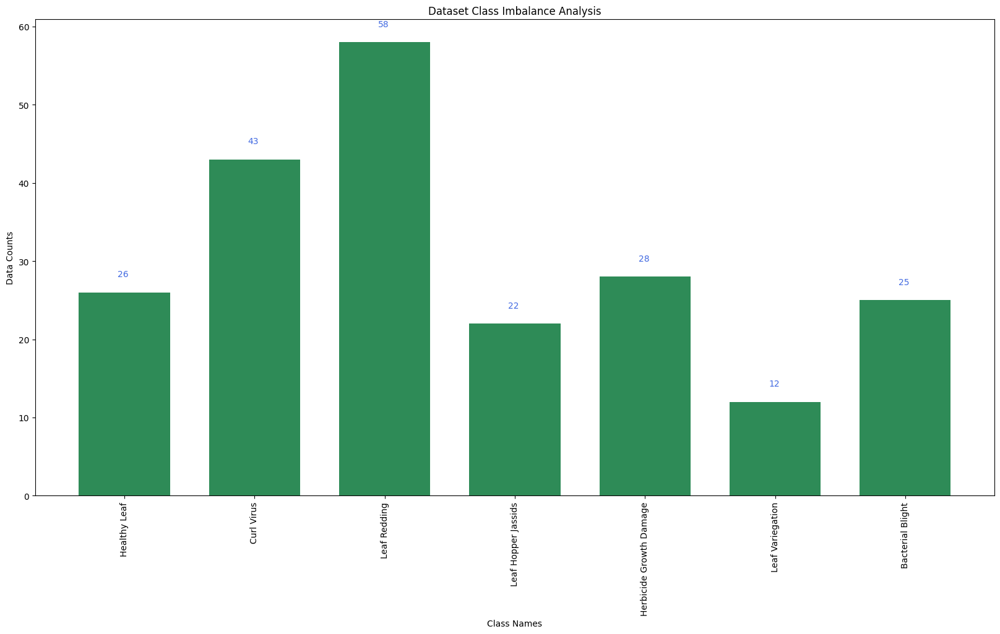

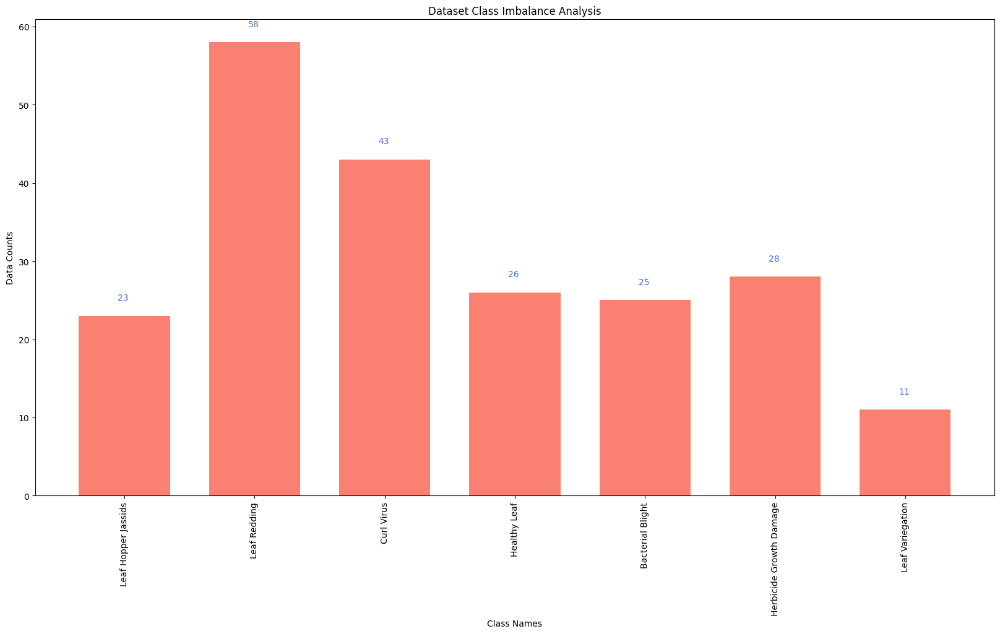

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from torchvision import transforms as T

class Visualization:

    def __init__(self, vis_datas, n_ims, rows, cmap=None, cls_names=None, cls_counts=None, t_type="rgb"):
        self.n_ims, self.rows = n_ims, rows
        self.t_type, self.cmap = t_type, cmap
        self.cls_names = cls_names
        
        data_names = ["train", "val", "test"]
        self.colors = ["darkorange", "seagreen", "salmon"] 
        self.vis_datas = {data_names[i]: vis_datas[i] for i in range(len(vis_datas))}
        if isinstance(cls_counts, list): 
            self.analysis_datas = {data_names[i]: cls_counts[i] for i in range(len(cls_counts))}
        else: 
            self.analysis_datas = {"all": cls_counts}

    def tn2np(self, t):
        gray_tfs = T.Compose([T.Normalize(mean=[0.], std=[1/0.5]), T.Normalize(mean=[-0.5], std=[1])])
        rgb_tfs = T.Compose([T.Normalize(mean=[0., 0., 0.], std=[1/0.229, 1/0.224, 1/0.225]), 
                             T.Normalize(mean=[-0.485, -0.456, -0.406], std=[1., 1., 1.])])
        
        invTrans = gray_tfs if self.t_type == "gray" else rgb_tfs
        
        return (invTrans(t) * 255).detach().squeeze().cpu().permute(1, 2, 0).numpy().astype(np.uint8) if self.t_type == "gray" \
               else (invTrans(t) * 255).detach().cpu().permute(1, 2, 0).numpy().astype(np.uint8)

    def plot(self, rows, cols, count, im, title="Original Image"):
        plt.subplot(rows, cols, count)
        plt.imshow(self.tn2np(im))
        plt.axis("off")
        plt.title(title)
        return count + 1

    def vis(self, data, save_name):
        print(f"{save_name.upper()} Data Visualization is in process...\n")
        assert self.cmap in ["rgb", "gray"], "Please choose rgb or gray cmap"
        cmap = "viridis" if self.cmap == "rgb" else None
        cols = self.n_ims // self.rows
        count = 1

        plt.figure(figsize=(25, 20))
        indices = [np.random.randint(low=0, high=len(data) - 1) for _ in range(self.n_ims)]

        for idx, index in enumerate(indices):
            if count == self.n_ims + 1: break
            image, label = data[index]
            plt.subplot(self.rows, self.n_ims // self.rows, idx + 1)

            if cmap:
                plt.imshow(self.tn2np(image), cmap=cmap)
            else:
                plt.imshow(self.tn2np(image))

            plt.axis('off')
            if self.cls_names is not None:
                plt.title(f"GT -> {self.cls_names[int(label)]}")
            else:
                plt.title(f"GT -> {label}")
        
        plt.show()

    def data_analysis(self, cls_counts, save_name, color):
        print("Data analysis is in process...\n")
        width, text_width, text_height = 0.7, 0.05, 2
        cls_names = list(cls_counts.keys())
        counts = list(cls_counts.values())
        _, ax = plt.subplots(figsize=(20, 10))
        indices = np.arange(len(counts))
        ax.bar(indices, counts, width, color=color)
        ax.set_xlabel("Class Names", color="black")
        ax.set_xticklabels(cls_names, rotation = 90)
        ax.set(xticks=indices, xticklabels=cls_names)
        ax.set_ylabel("Data Counts", color="black")
        ax.set_title("Dataset Class Imbalance Analysis")
        for i, v in enumerate(counts):
            ax.text(i - text_width, v + text_height, str(v), color="royalblue")
    
    def plot_pie_chart(self, cls_counts):
        print("Generating pie chart...\n")
        labels = list(cls_counts.keys())
        sizes = list(cls_counts.values())
        explode = [0.1] * len(labels)  # To highlight all slices equally (optional)
        
        plt.figure(figsize=(8, 8))
        plt.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
        plt.title("Class Distribution")
        plt.axis("equal")  # Equal aspect ratio ensures the pie chart is circular
        plt.show()

    def visualization(self): [self.vis(data.dataset, save_name) for (save_name, data) in self.vis_datas.items()]
        
    def analysis(self): [self.data_analysis(data, save_name, color) for (save_name, data), color in zip(self.analysis_datas.items(), self.colors)]

    def pie_chart(self): [self.plot_pie_chart(data) for data in self.analysis_datas.values()]
        
vis = Visualization(vis_datas = [tr_dl, val_dl, ts_dl], n_ims = 20, rows = 4, cmap = "rgb", cls_names = list(classes.keys()), cls_counts = cls_counts)
vis.analysis()

Generating pie chart...



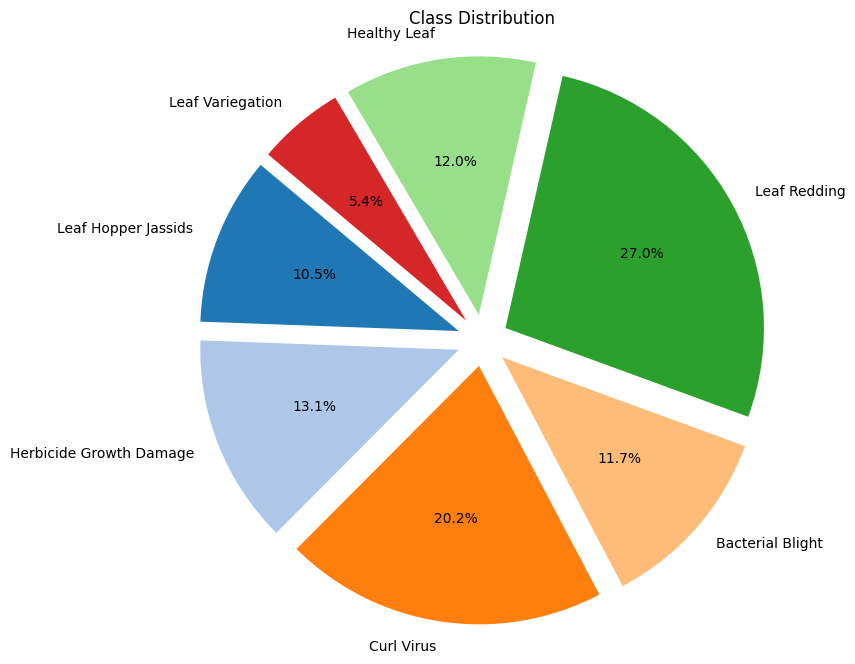

Generating pie chart...



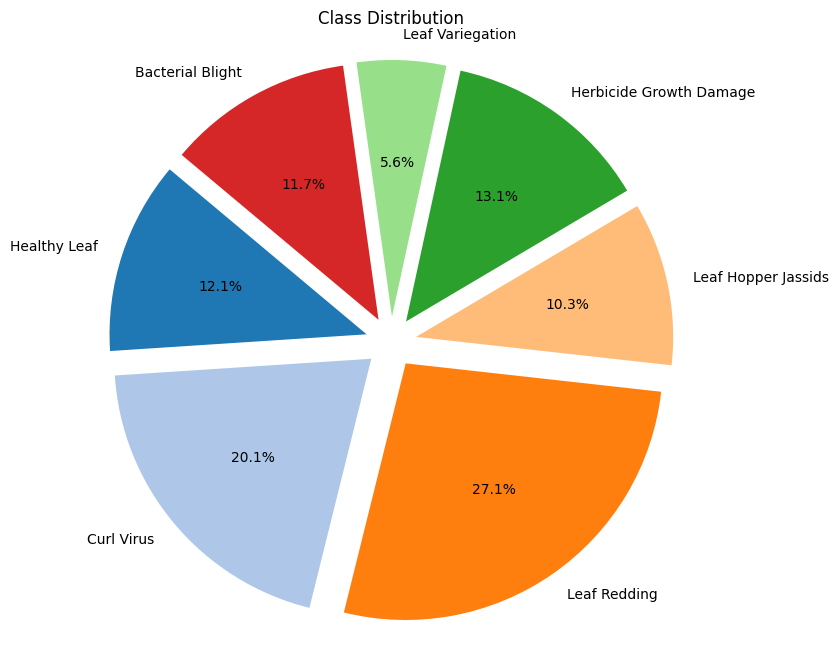

Generating pie chart...



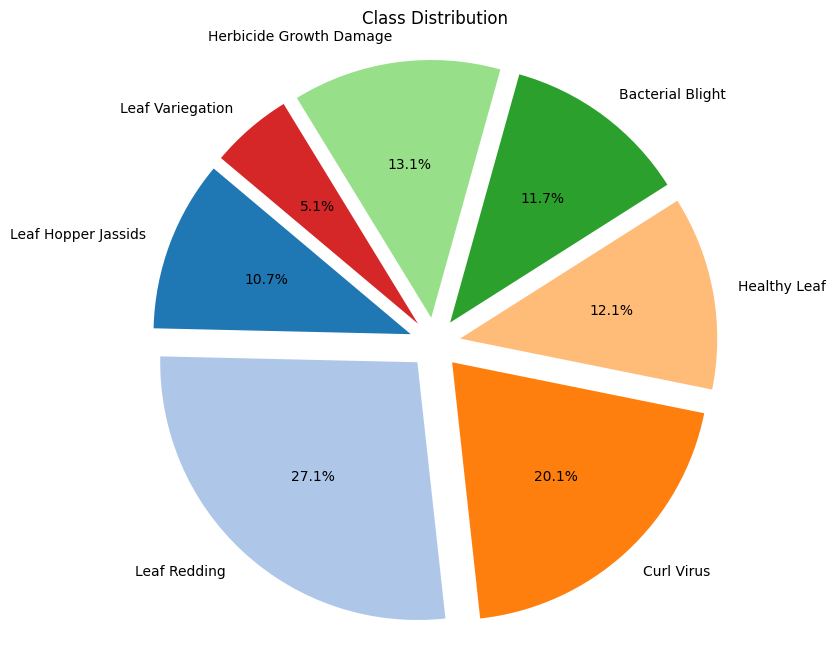

In [3]:
vis.pie_chart()

<div style='background-color: #e6f7ff; border: 3px solid #007acc; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#007acc"><b>📷 3. Data Visualization 📷</b></font>
</div>

TRAIN Data Visualization is in process...



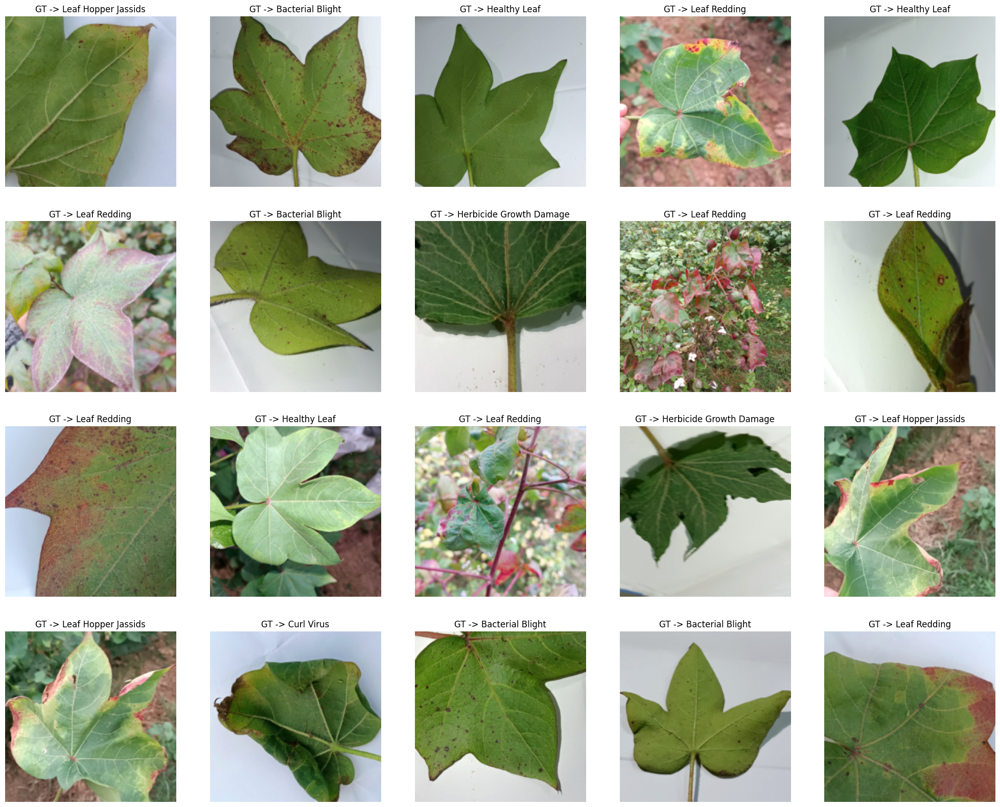

VAL Data Visualization is in process...



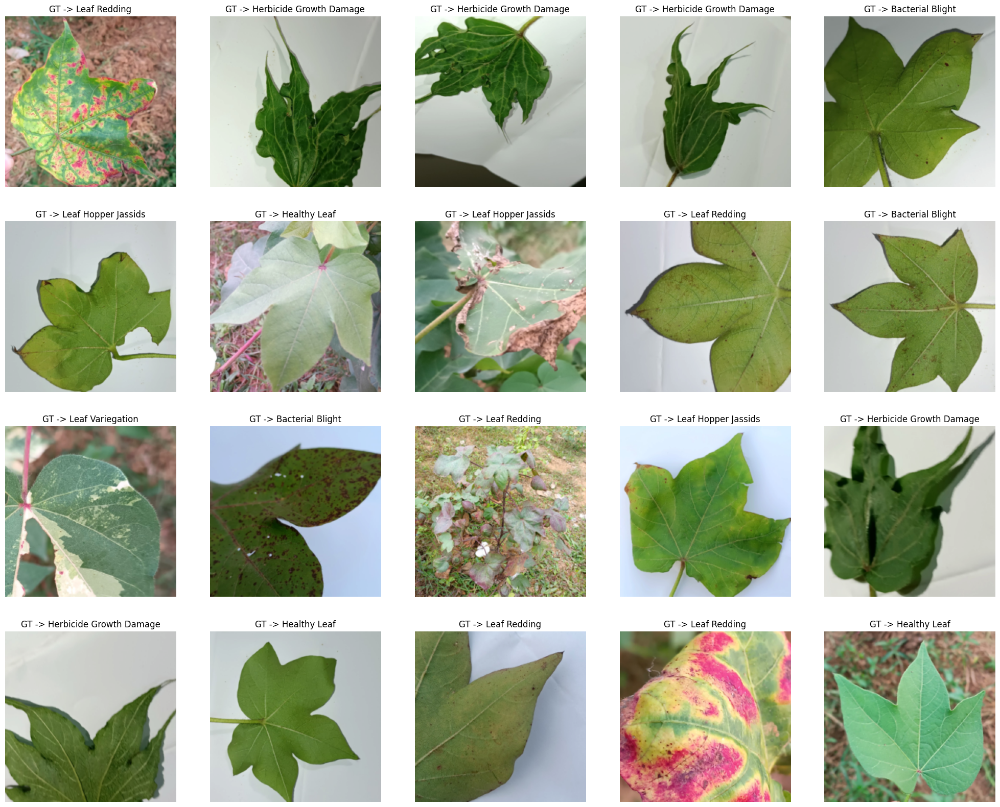

TEST Data Visualization is in process...



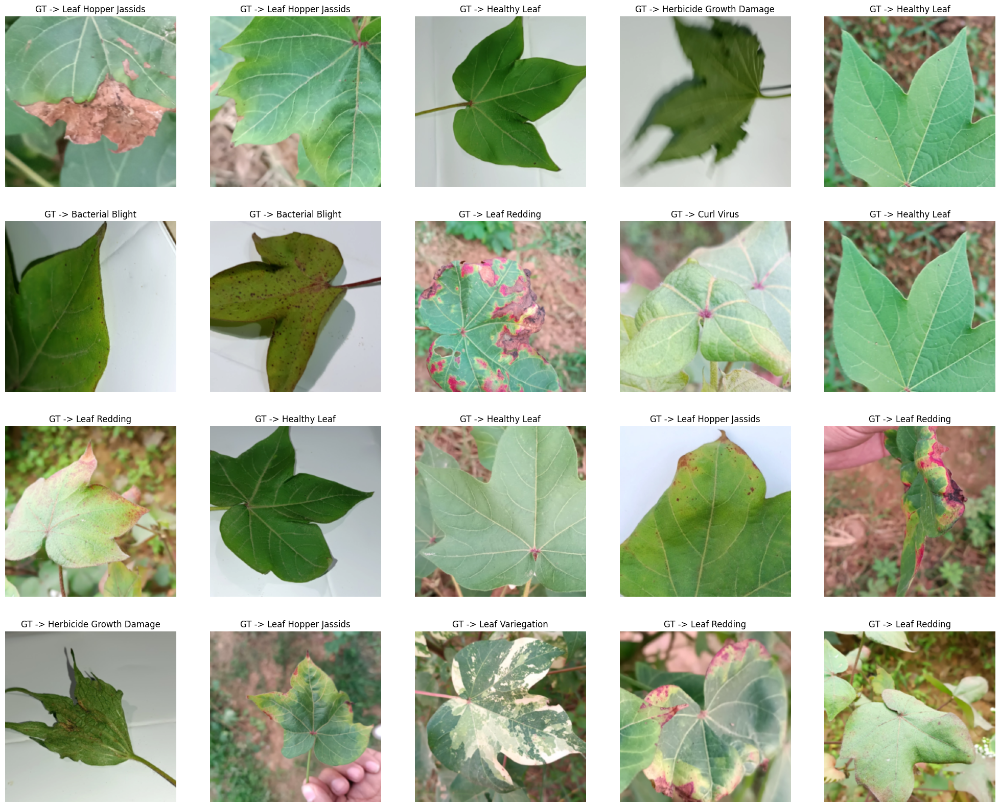

In [4]:
vis.visualization()

<div style='background-color: #f0f9e8; border: 3px solid #4CAF50; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#4CAF50"><b>⚙️ 4. Multi-Model Training & Validation ⚙️</b></font>
</div>

**Models being compared:**
| Model | Purpose | `timm` identifier |
| --- | --- | --- |
| ResNet50 | Strong baseline | `resnet50` |
| EfficientNet-B0 | Accuracy/efficiency balance | `efficientnet_b0` |
| MobileNetV3-Large | Mobile deployment | `mobilenetv3_large_100` |
| DenseNet121 | Strong classification | `densenet121` |

In [5]:
import os, torchmetrics, time
import timm
from tqdm import tqdm

class TrainValidation:
    def __init__(self, model_name, classes, tr_dl, val_dl, device, save_dir="saved_models", save_prefix="model", lr=3e-4, epochs=50, patience=5, threshold=0.01, dev_mode = False):
        self.model_name = model_name
        self.classes = classes
        self.tr_dl = tr_dl
        self.val_dl = val_dl
        self.save_dir = save_dir
        self.save_prefix = save_prefix
        self.lr = lr
        self.epochs = epochs
        self.patience = patience
        self.threshold = threshold
        self.dev_mode = dev_mode
        self.device = device
        self.model = timm.create_model(model_name, pretrained=True, num_classes=len(classes)).to(self.device)
        self.loss_fn = torch.nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(self.device)

        os.makedirs(save_dir, exist_ok=True)

        self.best_loss = float("inf")
        self.best_acc = 0
        self.not_improved = 0

        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []
        
        # Count parameters
        self.num_params = sum(p.numel() for p in self.model.parameters())
        self.trainable_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)

    @staticmethod
    def to_device(batch, device):
        ims, gts = batch
        return ims.to(device), gts.to(device)

    def train_epoch(self):
        self.model.train()
        train_loss, train_acc = 0.0, 0.0
        self.f1_metric.reset()

        for idx, batch in tqdm(enumerate(self.tr_dl), desc="Training"):
            if self.dev_mode: 
                if idx == 1: break
            
            ims, gts = TrainValidation.to_device(batch = batch, device = self.device)
            
            # Forward pass
            preds = self.model(ims)
            loss = self.loss_fn(preds, gts)
            
            # Backward pass
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            
            # Update metrics
            train_loss += loss.item() * gts.shape[0]
            train_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
            self.f1_metric.update(preds, gts)

        train_loss /= len(self.tr_dl.dataset)
        train_acc /= len(self.tr_dl.dataset)
        train_f1 = self.f1_metric.compute().item()
        
        self.tr_losses.append(train_loss)
        self.tr_accs.append(train_acc)
        self.tr_f1s.append(train_f1)

        return train_loss, train_acc, train_f1

    def validate_epoch(self):
        self.model.eval()
        val_loss, val_acc = 0.0, 0.0
        self.f1_metric.reset()

        with torch.no_grad():
            for idx, batch in tqdm(enumerate(self.val_dl), desc="Validation"):
                if self.dev_mode: 
                    if idx == 1: break
                ims, gts = TrainValidation.to_device(batch, device = self.device)
                preds = self.model(ims)
                loss = self.loss_fn(preds, gts)

                # Update metrics
                val_loss += loss.item() * gts.shape[0]
                val_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
                self.f1_metric.update(preds, gts)

        val_loss /= len(self.val_dl.dataset)
        val_acc /= len(self.val_dl.dataset)
        val_f1 = self.f1_metric.compute().item()

        self.val_losses.append(val_loss)
        self.val_accs.append(val_acc)
        self.val_f1s.append(val_f1)

        return val_loss, val_acc, val_f1

    def save_best_model(self, val_f1, val_loss):
        if val_f1 > self.best_acc + self.threshold:
            self.best_acc = val_f1            
            save_path = os.path.join(self.save_dir, f"{self.save_prefix}_best_model.pth")
            torch.save(self.model.state_dict(), save_path)
            print(f"Best model saved with F1-Score: {self.best_acc:.3f}")
            self.not_improved = 0
        else:
            self.not_improved += 1
            print(f"No improvement for {self.not_improved} epoch(s).")

    def verbose(self, epoch, metric1, metric2, metric3, process = "train"):
        print(f"{epoch + 1}-epoch {process} process is completed!\n")
        print(f"{epoch + 1}-epoch {process} loss          -> {metric1:.3f}")
        print(f"{epoch + 1}-epoch {process} accuracy      -> {metric2:.3f}")
        print(f"{epoch + 1}-epoch {process} f1-score      -> {metric3:.3f}\n")
    
    def run(self):
        print("Start training...")

        for epoch in range(self.epochs):
            if self.dev_mode: 
                if epoch == 1: break 
                    
            print(f"\nEpoch {epoch + 1}/{self.epochs}:\n")

            train_loss, train_acc, train_f1 = self.train_epoch()
            self.verbose(epoch, train_loss, train_acc, train_f1, process = "train")

            val_loss, val_acc, val_f1 = self.validate_epoch()
            self.verbose(epoch, val_loss, val_acc, val_f1, process = "validation")            

            self.save_best_model(val_f1, val_loss)

            if self.not_improved >= self.patience:
                print("Early stopping triggered.")
                break

In [6]:
# ============================================================================
# MODEL CONFIGURATIONS
# ============================================================================
MODEL_CONFIGS = {
    "ResNet50":           "resnet50",
    "EfficientNet-B0":    "efficientnet_b0",
    "MobileNetV3-Large":  "mobilenetv3_large_100",
    "DenseNet121":        "densenet121",
}

save_dir = "saved_models"
device   = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# ============================================================================
# TRAIN ALL MODELS
# ============================================================================
all_results = {}

for display_name, timm_name in MODEL_CONFIGS.items():
    print(f"\n{'='*80}")
    print(f"  TRAINING: {display_name} ({timm_name})")
    print(f"{'='*80}\n")
    
    save_prefix = display_name.lower().replace("-", "_").replace(" ", "_")
    
    trainer = TrainValidation(
        model_name  = timm_name,
        device      = device,
        save_prefix = save_prefix,
        save_dir    = save_dir,
        classes     = classes,
        patience    = 3,
        tr_dl       = tr_dl,
        val_dl      = val_dl,
        dev_mode    = False
    )
    
    start_time = time.time()
    trainer.run()
    training_time = time.time() - start_time
    
    all_results[display_name] = {
        "timm_name":        timm_name,
        "save_prefix":      save_prefix,
        "trainer":          trainer,
        "tr_losses":        trainer.tr_losses,
        "val_losses":       trainer.val_losses,
        "tr_accs":          trainer.tr_accs,
        "val_accs":         trainer.val_accs,
        "tr_f1s":           trainer.tr_f1s,
        "val_f1s":          trainer.val_f1s,
        "best_val_f1":      trainer.best_acc,
        "best_val_acc":     max(trainer.val_accs) if trainer.val_accs else 0,
        "best_val_loss":    min(trainer.val_losses) if trainer.val_losses else float("inf"),
        "num_params":       trainer.num_params,
        "trainable_params": trainer.trainable_params,
        "training_time":    training_time,
        "epochs_trained":   len(trainer.tr_losses),
    }
    
    print(f"\n{display_name} -> Best Val F1: {trainer.best_acc:.4f} | "
          f"Params: {trainer.num_params/1e6:.2f}M | "
          f"Time: {training_time:.1f}s\n")

# ============================================================================
# SUMMARY TABLE
# ============================================================================
print("\n" + "="*100)
print(f"{'MODEL COMPARISON SUMMARY':^100}")
print("="*100)
print(f"{'Model':<22} {'Best Val Acc':>12} {'Best Val F1':>12} {'Best Val Loss':>14} {'Params (M)':>12} {'Time (min)':>12} {'Epochs':>8}")
print("-"*100)

for name, res in all_results.items():
    print(f"{name:<22} {res['best_val_acc']:>12.4f} {res['best_val_f1']:>12.4f} {res['best_val_loss']:>14.4f} {res['num_params']/1e6:>12.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8}")

print("-"*100)
best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
print(f"\n🏆 BEST MODEL: {best_model_name} (Val F1 = {all_results[best_model_name]['best_val_f1']:.4f})")

Using device: cuda

  TRAINING: ResNet50 (resnet50)



model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Start training...

Epoch 1/50:



Training: 107it [00:19,  5.45it/s]


1-epoch train process is completed!

1-epoch train loss          -> 1.359
1-epoch train accuracy      -> 0.516
1-epoch train f1-score      -> 0.516



Validation: 14it [00:01,  9.38it/s]


... (107 outputs left out)

Training: 107it [00:19,  5.41it/s]

4-epoch train process is completed!

4-epoch train loss          -> 0.077
4-epoch train accuracy      -> 0.977
4-epoch train f1-score      -> 0.977




Validation: 14it [00:01, 11.38it/s]

4-epoch validation process is completed!

4-epoch validation loss          -> 0.097
4-epoch validation accuracy      -> 0.958
4-epoch validation f1-score      -> 0.958

No improvement for 3 epoch(s).
Early stopping triggered.

DenseNet121 -> Best Val F1: 0.9673 | Params: 6.96M | Time: 85.4s


                                      MODEL COMPARISON SUMMARY                                      
Model                  Best Val Acc  Best Val F1  Best Val Loss   Params (M)   Time (min)   Epochs
----------------------------------------------------------------------------------------------------
ResNet50                     0.9720       0.9720         0.0760        23.52          3.3        9
EfficientNet-B0              0.9766       0.9766         0.0898         4.02          1.5        8
MobileNetV3-Large            0.9673       0.9626         0.1362         4.21          0.9        6
DenseNet121                  0.9766       0.9673         0.0777         6.96          1.4        4
---------

<div style='background-color: #fff0f5; border: 3px solid #FF69B4; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#FF1493"><b>😍 5. Per-Model Learning Curves 😍</b></font>
</div>


  Learning Curves: ResNet50


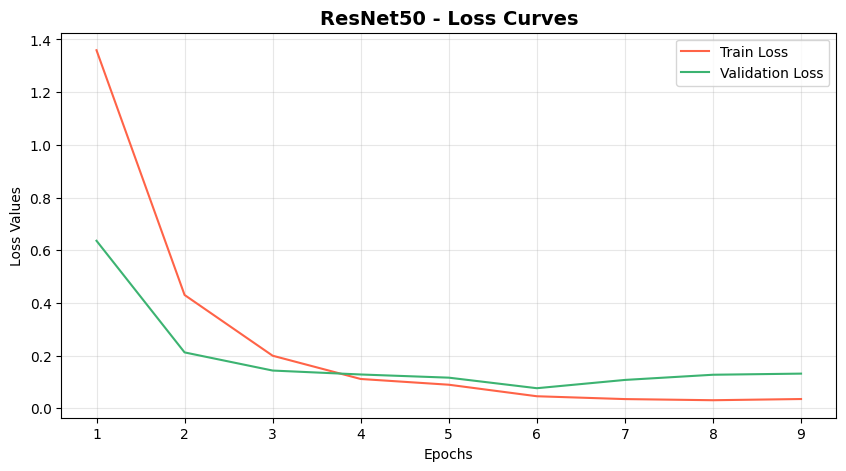

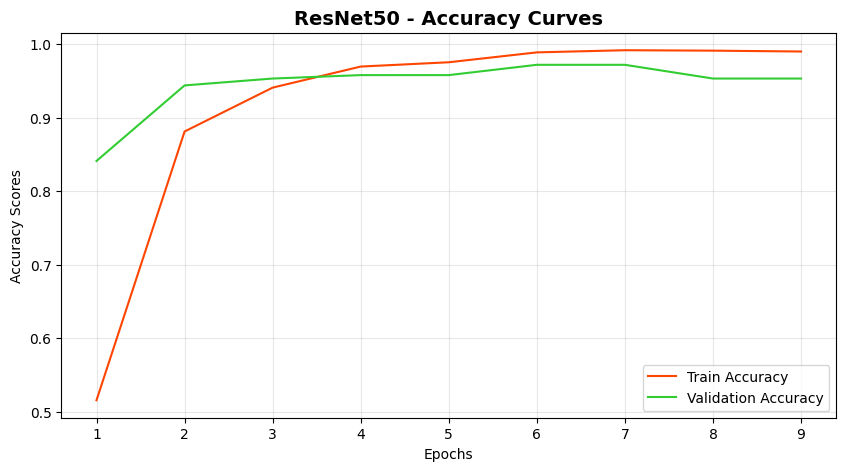

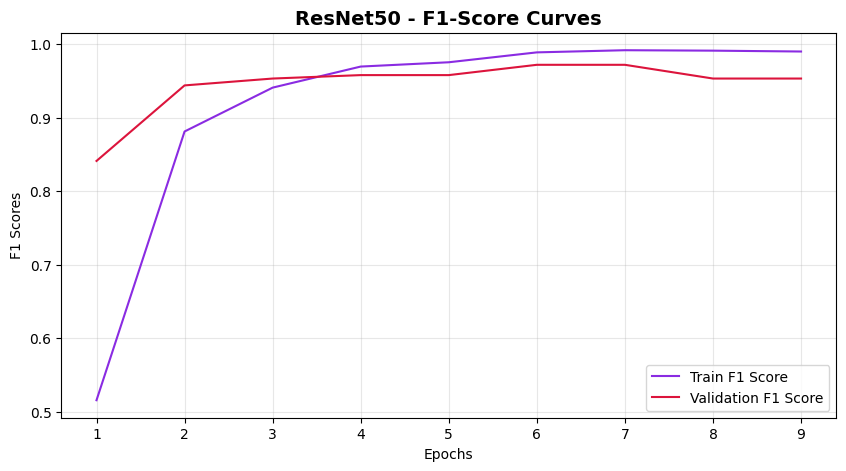


  Learning Curves: EfficientNet-B0


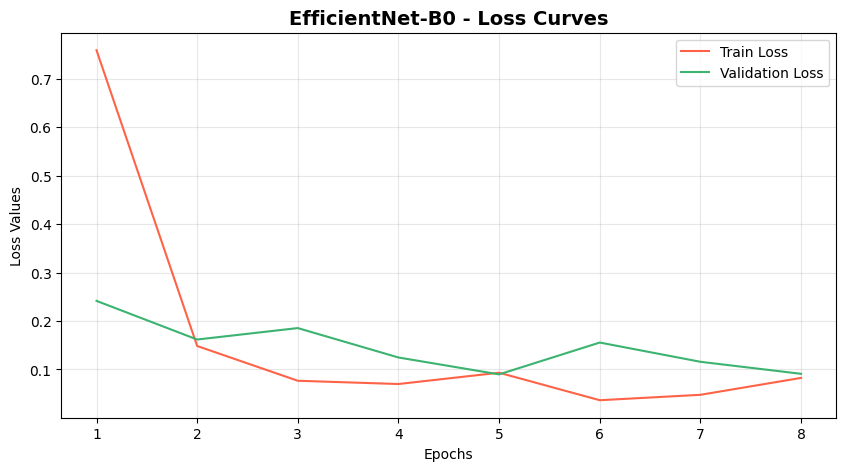

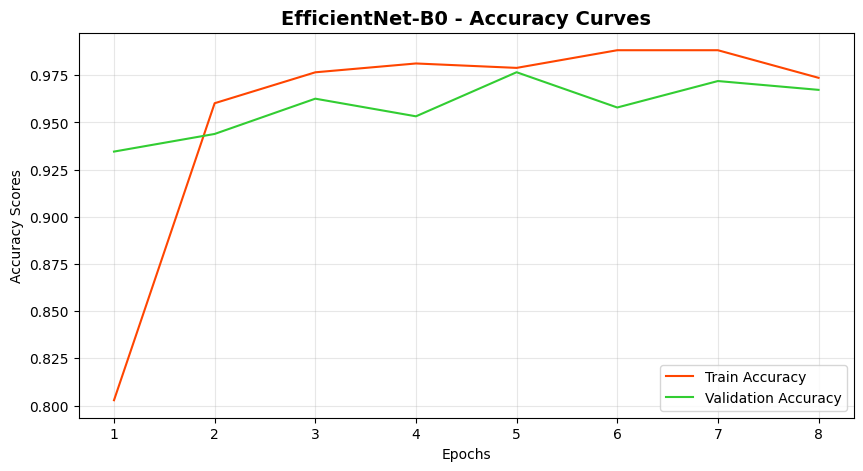

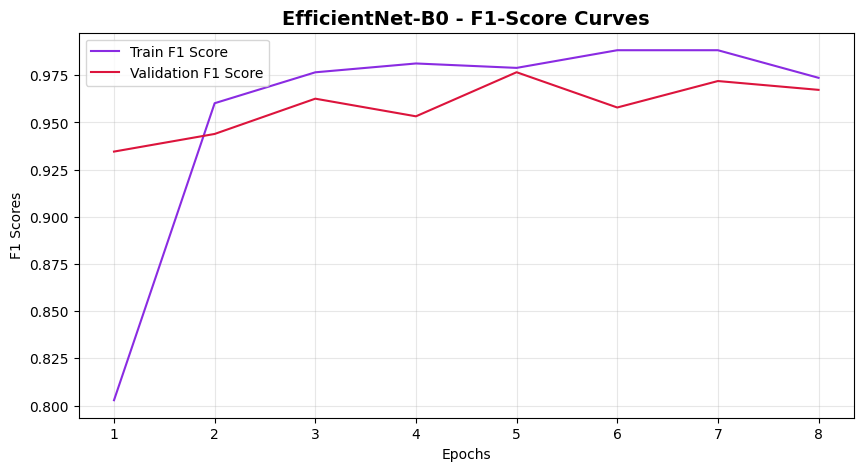


  Learning Curves: MobileNetV3-Large


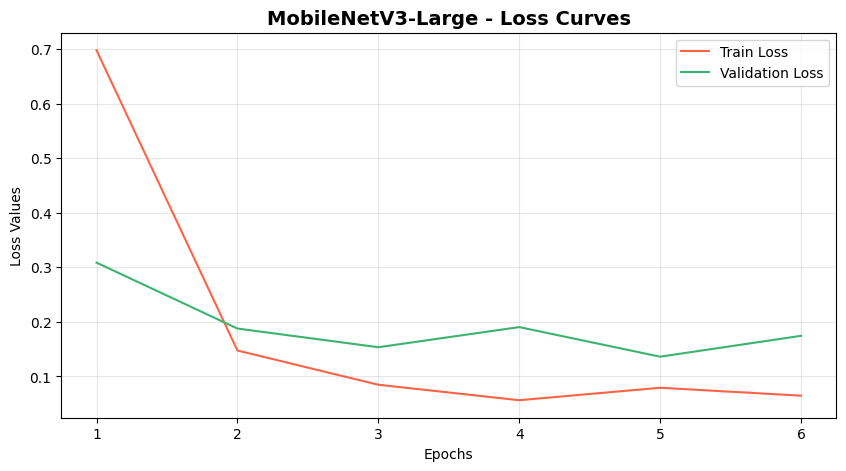

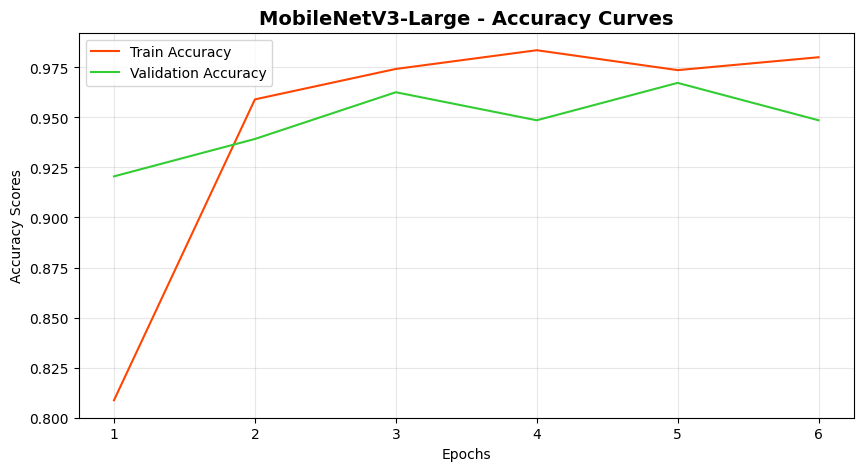

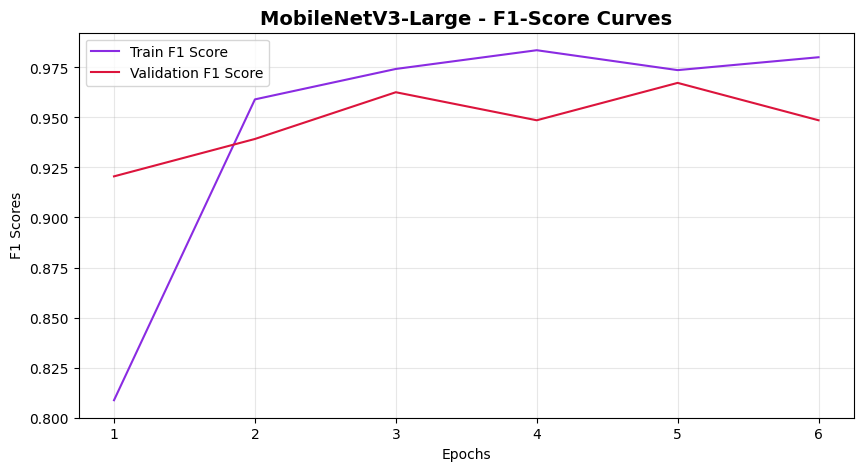


  Learning Curves: DenseNet121


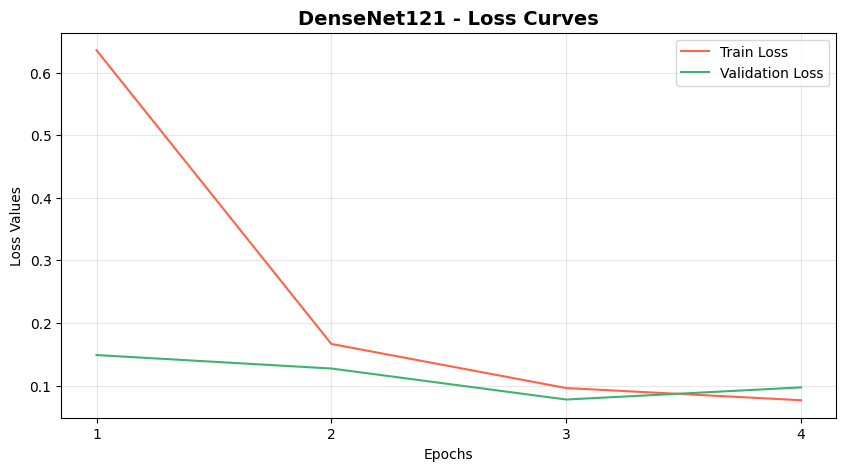

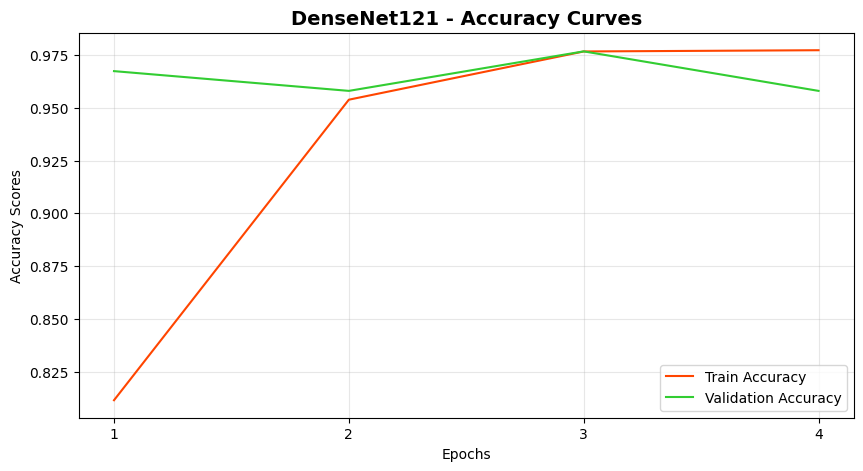

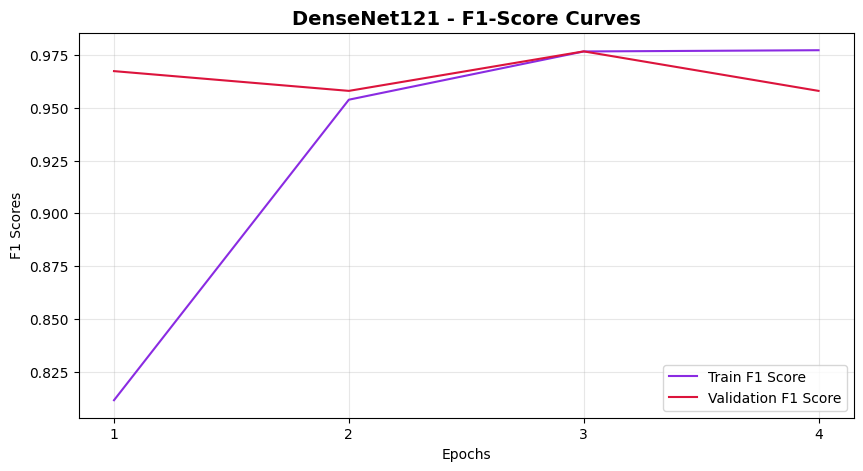

In [7]:
class PlotLearningCurves:
    
    def __init__(self, tr_losses, val_losses, tr_accs, val_accs, tr_f1s, val_f1s, model_name="Model"):
        self.tr_losses, self.val_losses = tr_losses, val_losses
        self.tr_accs, self.val_accs = tr_accs, val_accs
        self.tr_f1s, self.val_f1s = tr_f1s, val_f1s
        self.model_name = model_name
        
    def plot(self, array_1, array_2, label_1, label_2, color_1, color_2):
        plt.plot(array_1, label = label_1, c = color_1)
        plt.plot(array_2, label = label_2, c = color_2)
        
    def create_figure(self): 
        plt.figure(figsize = (10, 5))
    
    def decorate(self, ylabel, title="", xlabel = "Epochs"): 
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.title(title, fontsize=14, fontweight='bold')
        plt.xticks(ticks = np.arange(len(self.tr_accs)), labels = [i for i in range(1, len(self.tr_accs) + 1)])
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()      
        
    def visualize(self):
        # Figure 1: Loss Curves
        self.create_figure()
        self.plot(array_1 = self.tr_losses, array_2 = self.val_losses, label_1 = "Train Loss", label_2 = "Validation Loss", color_1 = "#FF6347", color_2 = "#3CB371")
        self.decorate(ylabel = "Loss Values", title=f"{self.model_name} - Loss Curves")
        
        # Figure 2: Accuracy Curves
        self.create_figure()
        self.plot(array_1 = self.tr_accs, array_2 = self.val_accs, label_1 = "Train Accuracy", label_2 = "Validation Accuracy", color_1 = "#FF4500", color_2 = "#32CD32")
        self.decorate(ylabel = "Accuracy Scores", title=f"{self.model_name} - Accuracy Curves")
        
        # Figure 3: F1 Score Curves
        self.create_figure()
        self.plot(array_1 = self.tr_f1s, array_2 = self.val_f1s, label_1 = "Train F1 Score", label_2 = "Validation F1 Score", color_1 = "#8A2BE2", color_2 = "#DC143C")
        self.decorate(ylabel = "F1 Scores", title=f"{self.model_name} - F1-Score Curves")

for model_name, res in all_results.items():
    print(f"\n{'='*60}")
    print(f"  Learning Curves: {model_name}")
    print(f"{'='*60}")
    PlotLearningCurves(
        tr_losses=res['tr_losses'], val_losses=res['val_losses'],
        tr_accs=res['tr_accs'], val_accs=res['val_accs'],
        tr_f1s=res['tr_f1s'], val_f1s=res['val_f1s'],
        model_name=model_name
    ).visualize()

<div style='background-color: #f5f0ff; border: 3px solid #7c3aed; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#7c3aed"><b>📊 6. Multi-Model Comparison Graphs 📊</b></font>
</div>

Comprehensive side-by-side comparison of all trained models across multiple metrics.

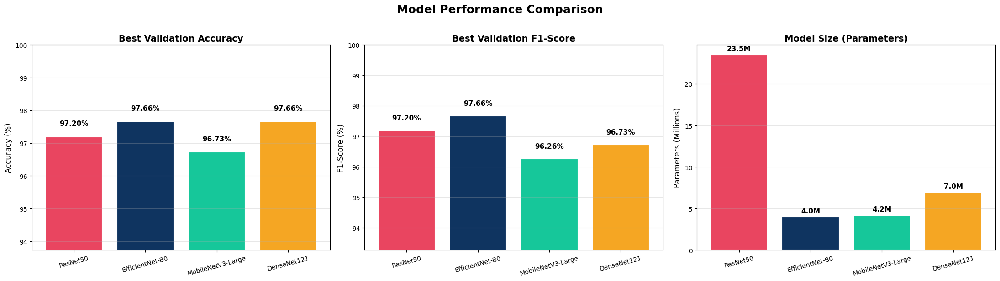

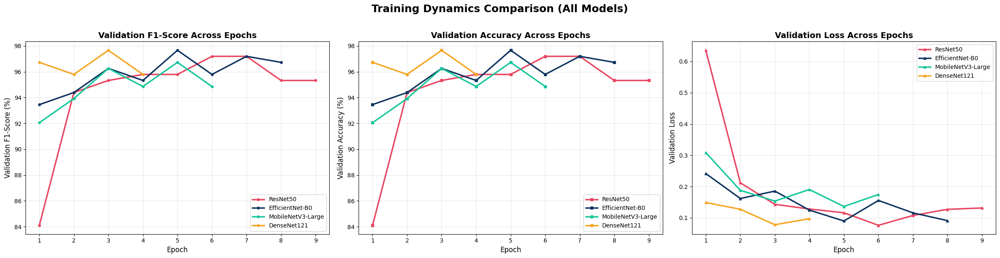

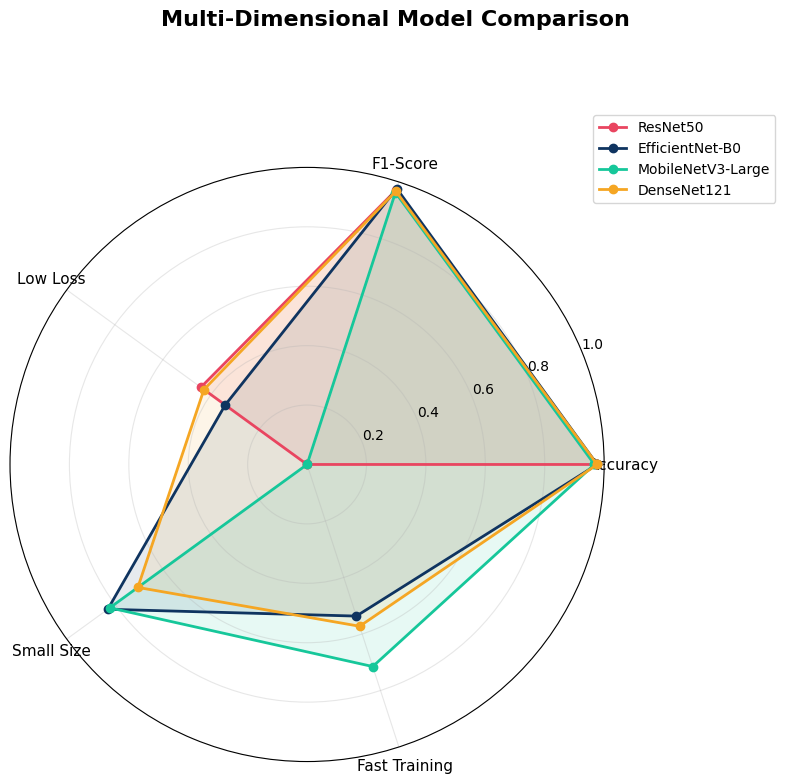

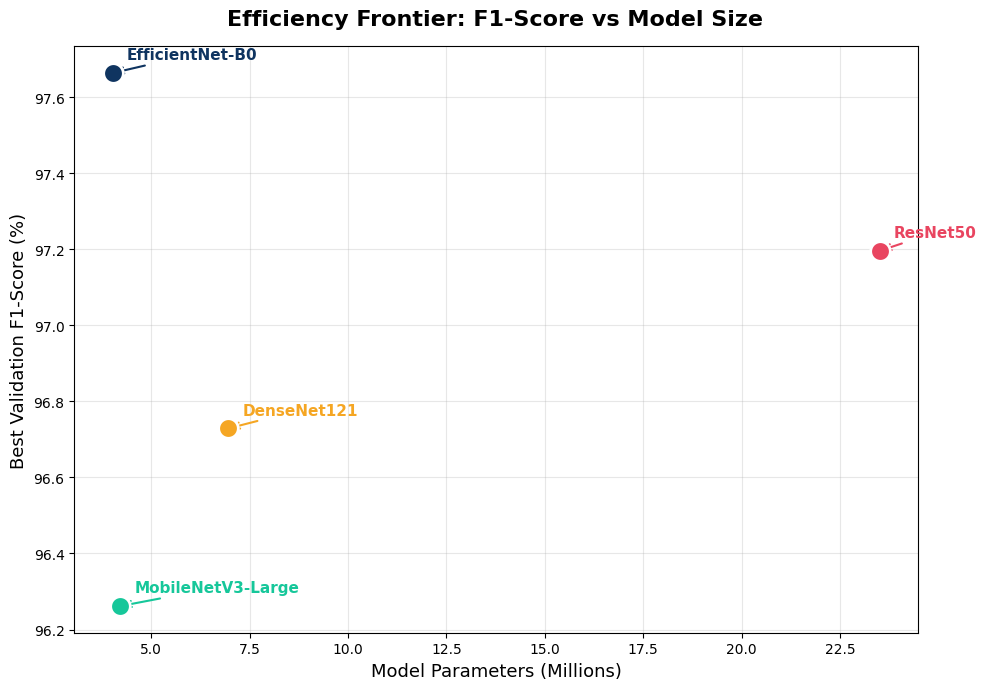

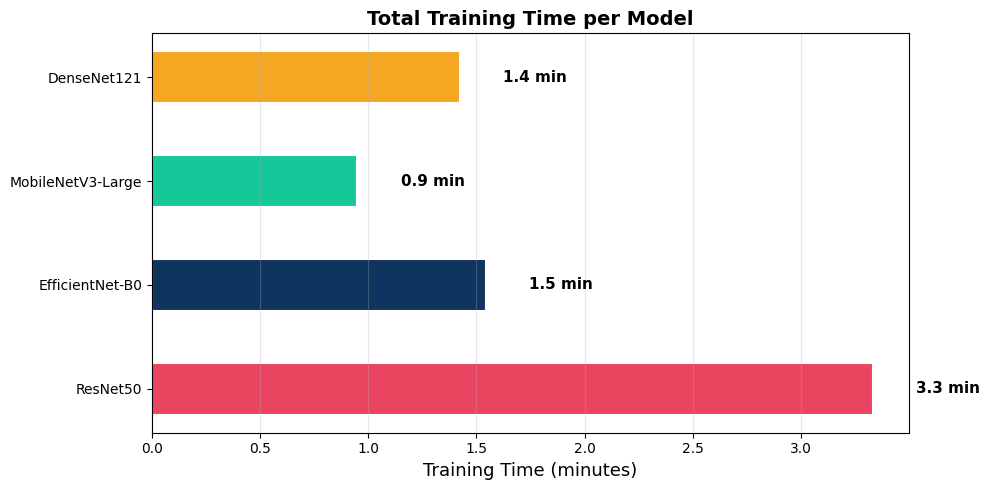


                                        COMPREHENSIVE MODEL COMPARISON                                        
Model                   Accuracy (%)     F1 (%)       Loss   Params (M)   Time (min)   Epochs    Params/F1
--------------------------------------------------------------------------------------------------------------
ResNet50                       97.20      97.20     0.0760        23.52          3.3        9       0.2420
EfficientNet-B0                97.66      97.66     0.0898         4.02          1.5        8       0.0411
MobileNetV3-Large              96.73      96.26     0.1362         4.21          0.9        6       0.0437
DenseNet121                    97.66      96.73     0.0777         6.96          1.4        4       0.0720
--------------------------------------------------------------------------------------------------------------

🏆 BEST ACCURACY/F1: EfficientNet-B0 (F1 = 97.66%)
⚡ MOST EFFICIENT: EfficientNet-B0
📱 BEST FOR MOBILE: MobileNetV3-Large (4.21M pa

In [8]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

MODEL_COLORS = {
    "ResNet50":           "#e94560",   # Coral Red
    "EfficientNet-B0":    "#0f3460",   # Deep Navy
    "MobileNetV3-Large":  "#16c79a",   # Mint Green
    "DenseNet121":        "#f5a623",   # Amber Gold
}

model_names = list(all_results.keys())
colors = [MODEL_COLORS.get(name, "#888") for name in model_names]

# 1. BAR CHARTS
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle("Model Performance Comparison", fontsize=18, fontweight='bold', y=1.02)

accs = [all_results[n]['best_val_acc'] * 100 for n in model_names]
bars = axes[0].bar(model_names, accs, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_ylabel("Accuracy (%)", fontsize=12)
axes[0].set_title("Best Validation Accuracy", fontsize=14, fontweight='bold')
axes[0].set_ylim([min(accs) - 3, 100])
for bar, val in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.2f}%", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.3)

f1s = [all_results[n]['best_val_f1'] * 100 for n in model_names]
bars = axes[1].bar(model_names, f1s, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylabel("F1-Score (%)", fontsize=12)
axes[1].set_title("Best Validation F1-Score", fontsize=14, fontweight='bold')
axes[1].set_ylim([min(f1s) - 3, 100])
for bar, val in zip(bars, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.2f}%", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', alpha=0.3)

params = [all_results[n]['num_params'] / 1e6 for n in model_names]
bars = axes[2].bar(model_names, params, color=colors, edgecolor='white', linewidth=1.5)
axes[2].set_ylabel("Parameters (Millions)", fontsize=12)
axes[2].set_title("Model Size (Parameters)", fontsize=14, fontweight='bold')
for bar, val in zip(bars, params):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}M", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[2].tick_params(axis='x', rotation=15)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 2. OVERLAY CURVES
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
fig.suptitle("Training Dynamics Comparison (All Models)", fontsize=18, fontweight='bold', y=1.02)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_f1s']) + 1)
    axes[0].plot(epochs_range, [f*100 for f in all_results[name]['val_f1s']], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='o', markersize=4)
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Validation F1-Score (%)", fontsize=12)
axes[0].set_title("Validation F1-Score Across Epochs", fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10, loc='lower right')
axes[0].grid(alpha=0.3)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_accs']) + 1)
    axes[1].plot(epochs_range, [a*100 for a in all_results[name]['val_accs']], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='s', markersize=4)
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Validation Accuracy (%)", fontsize=12)
axes[1].set_title("Validation Accuracy Across Epochs", fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10, loc='lower right')
axes[1].grid(alpha=0.3)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_losses']) + 1)
    axes[2].plot(epochs_range, all_results[name]['val_losses'], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='^', markersize=4)
axes[2].set_xlabel("Epoch", fontsize=12)
axes[2].set_ylabel("Validation Loss", fontsize=12)
axes[2].set_title("Validation Loss Across Epochs", fontsize=14, fontweight='bold')
axes[2].legend(fontsize=10, loc='upper right')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. RADAR CHART
from math import pi
categories = ['Accuracy', 'F1-Score', 'Low Loss', 'Small Size', 'Fast Training']
N = len(categories)
max_params = max(all_results[n]['num_params'] for n in model_names)
max_time = max(all_results[n]['training_time'] for n in model_names)
max_loss = max(all_results[n]['best_val_loss'] for n in model_names)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.suptitle("Multi-Dimensional Model Comparison", fontsize=16, fontweight='bold', y=1.02)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

for name in model_names:
    res = all_results[name]
    values = [
        res['best_val_acc'],
        res['best_val_f1'],
        1 - (res['best_val_loss'] / max_loss) if max_loss > 0 else 1,
        1 - (res['num_params'] / max_params),
        1 - (res['training_time'] / max_time) if max_time > 0 else 1,
    ]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=MODEL_COLORS.get(name))
    ax.fill(angles, values, alpha=0.1, color=MODEL_COLORS.get(name))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. SCATTER PLOT
fig, ax = plt.subplots(figsize=(10, 7))
fig.suptitle("Efficiency Frontier: F1-Score vs Model Size", fontsize=16, fontweight='bold')

for name in model_names:
    res = all_results[name]
    ax.scatter(res['num_params']/1e6, res['best_val_f1']*100, 
              s=200, c=MODEL_COLORS.get(name), edgecolors='white', linewidth=2, zorder=5)
    ax.annotate(name, (res['num_params']/1e6, res['best_val_f1']*100),
               textcoords="offset points", xytext=(10, 10), fontsize=11, fontweight='bold',
               color=MODEL_COLORS.get(name),
               arrowprops=dict(arrowstyle='->', color=MODEL_COLORS.get(name), lw=1.5))

ax.set_xlabel("Model Parameters (Millions)", fontsize=13)
ax.set_ylabel("Best Validation F1-Score (%)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. TRAINING TIME
fig, ax = plt.subplots(figsize=(10, 5))
times = [all_results[n]['training_time'] / 60 for n in model_names]
bars = ax.barh(model_names, times, color=colors, edgecolor='white', linewidth=1.5, height=0.5)
for bar, val in zip(bars, times):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.1f} min", 
           va='center', fontweight='bold', fontsize=11)
ax.set_xlabel("Training Time (minutes)", fontsize=13)
ax.set_title("Total Training Time per Model", fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# 6. SUMMARY TABLE
print("\n" + "="*110)
print(f"{'COMPREHENSIVE MODEL COMPARISON':^110}")
print("="*110)
print(f"{'Model':<22} {'Accuracy (%)':>13} {'F1 (%)':>10} {'Loss':>10} {'Params (M)':>12} {'Time (min)':>12} {'Epochs':>8} {'Params/F1':>12}")
print("-"*110)

for name in model_names:
    res = all_results[name]
    efficiency = (res['num_params']/1e6) / (res['best_val_f1']*100) if res['best_val_f1'] > 0 else float('inf')
    print(f"{name:<22} {res['best_val_acc']*100:>13.2f} {res['best_val_f1']*100:>10.2f} {res['best_val_loss']:>10.4f} "
          f"{res['num_params']/1e6:>12.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8} {efficiency:>12.4f}")

print("-"*110)
best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
most_efficient = min(all_results, key=lambda k: (all_results[k]['num_params']/1e6) / (all_results[k]['best_val_f1']*100) if all_results[k]['best_val_f1'] > 0 else float('inf'))
print(f"\n🏆 BEST ACCURACY/F1: {best_model_name} (F1 = {all_results[best_model_name]['best_val_f1']*100:.2f}%)")
print(f"⚡ MOST EFFICIENT: {most_efficient}")
print(f"📱 BEST FOR MOBILE: MobileNetV3-Large ({all_results.get('MobileNetV3-Large', {}).get('num_params', 0)/1e6:.2f}M params)")

<div style='background-color: #fff0db; border: 3px solid #FFA07A; border-radius: 10px; padding: 6px; text-align: center;'>
    <font size="+1.8" color="#FF4500"><b>✅ 7. Inference and AI Model Performance Analysis with GradCAM ✅</b></font>
</div>

Evaluate the **best-performing model** on the test set with GradCAM visualization, confusion matrix, and full classification report.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 8.4 MB/s eta 0:00:0000:0100:01m
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.4.6-py3-none-any.whl size=38339 sha256=939707b54051fca7c1d1aa8884c23a149127580ab9730e46d441498577a6d86d
  Stored in directory: /root/.cache/pip/wheels/02/26/f1/92ac7f7699f6f0849e03e212b8b0bb8d2c3d7b2723aa474b22
Successfully built grad-cam

Evaluating best model: EfficientNet-B0 (efficientnet_b0)
Loading checkpoint: saved_models/efficientnet_b0_best_model.pth



Inference: 214it [00:03, 67.53it/s]



Accuracy of the model on the test data -> 0.944
F1 score of the model on the test data -> 0.944

DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     0.9167    0.8800    0.8980        25
             Curl Virus     0.9545    0.9767    0.9655        43
           Healthy Leaf     0.8571    0.9231    0.8889        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     0.9524    0.8696    0.9091        23
           Leaf Redding     0.9483    0.9483    0.9483        58
       Leaf Variegation     1.0000    1.0000    1.0000        11

               accuracy                         0.9439       214
              macro avg     0.9470    0.9425    0.9442       214
           weighted avg     0.9446    0.9439    0.9439       214



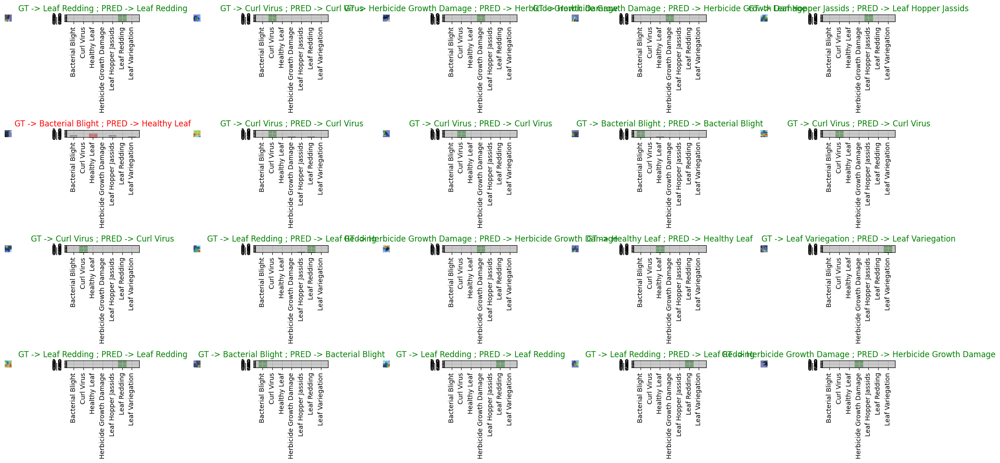

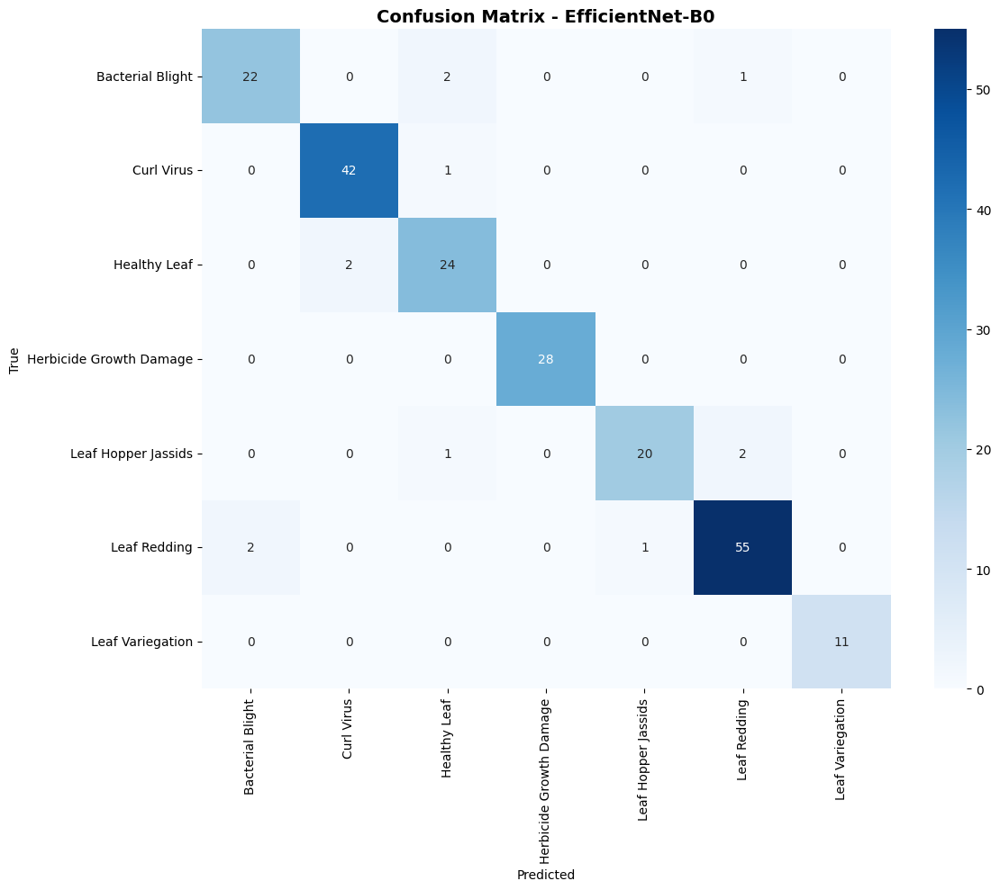

In [9]:
!pip install grad-cam==1.4.6
import cv2, random
import seaborn as sns
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

class Denormalize:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        for t, m, s in zip(tensor, self.mean, self.std):
            t.mul_(s).add_(m)
        return tensor

def get_gradcam_target_layer(model, timm_name):
    """Get the correct GradCAM target layer for each architecture."""
    if "resnet" in timm_name:
        return [model.layer4[-1]]
    elif "efficientnet" in timm_name:
        return [model.blocks[-1]]
    elif "mobilenetv3" in timm_name:
        return [model.blocks[-1]]
    elif "densenet" in timm_name:
        return [model.features.denseblock4]
    else:
        if hasattr(model, 'features'):
            return [model.features[-1]]
        elif hasattr(model, 'blocks'):
            return [model.blocks[-1]]
        else:
            return [list(model.children())[-2]]

class ModelInferenceVisualizer:
    def __init__(self, model, device, timm_name, class_names=None, im_size=224, mean=mean, std=std):
        self.denormalize = Denormalize(mean, std)
        self.model = model
        self.device = device
        self.timm_name = timm_name
        self.class_names = class_names
        self.im_size = im_size
        self.model.eval()
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(class_names)).to(self.device)

    def tensor_to_image(self, tensor):
        tensor = self.denormalize(tensor)
        tensor = tensor.permute(1, 2, 0)
        return (tensor.cpu().numpy() * 255).astype(np.uint8)

    def plot_value_array(self, logits, gt, class_names):
        probs = torch.nn.functional.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1)
        
        plt.grid(visible=True)
        plt.xticks(range(len(class_names)), class_names, rotation='vertical')
        plt.yticks(np.arange(0.0, 1.1, 0.1))
        bars = plt.bar(range(len(class_names)), [p.item() for p in probs[0]], color="#777777")
        plt.ylim([0, 1])
        if pred_class.item() == gt:
            bars[pred_class].set_color('green')
        else:
            bars[pred_class].set_color('red')

    def generate_cam_visualization(self, image_tensor):
        target_layers = get_gradcam_target_layer(self.model, self.timm_name)
        cam = GradCAMPlusPlus(model=self.model, target_layers=target_layers)
        input_t = image_tensor.unsqueeze(0).to(self.device)
        grayscale_cam = cam(input_tensor=input_t)[0, :]
        return grayscale_cam

    def infer_and_visualize(self, test_dl, num_images=5, rows=2):
        preds, images, lbls, logitss = [], [], [], []
        accuracy, count = 0, 1

        with torch.no_grad():
            for idx, batch in tqdm(enumerate(test_dl), desc="Inference"):
                im, gt = TrainValidation.to_device(batch, device=self.device)                
                logits = self.model(im)
                pred_class = torch.argmax(logits, dim=1)
                
                accuracy += (pred_class == gt).sum().item()
                self.f1_metric.update(logits, gt)  
        
                images.append(im[0].cpu())
                logitss.append(logits[0])
                preds.append(pred_class[0].item())
                lbls.append(gt[0].item())
        
        test_acc = accuracy / len(test_dl.dataset)
        test_f1 = self.f1_metric.compute().item()
        print(f"\nAccuracy of the model on the test data -> {test_acc:.3f}")
        print(f"F1 score of the model on the test data -> {test_f1:.3f}") 
        
        print(f"\n{'='*60}")
        print("DETAILED CLASSIFICATION REPORT")
        print(f"{'='*60}")
        print(classification_report(lbls, preds, target_names=self.class_names, digits=4))

        plt.figure(figsize=(20, 10))
        indices = [random.randint(0, len(images) - 1) for _ in range(num_images)]
        for idx, index in enumerate(indices):
            im = self.tensor_to_image(images[index].squeeze())
            pred_idx = preds[index]
            gt_idx = lbls[index]

            plt.subplot(rows, 2 * num_images // rows, count)
            count += 1
            plt.imshow(im, cmap="gray")
            plt.axis("off")

            grayscale_cam = self.generate_cam_visualization(images[index])
            visualization = show_cam_on_image(im / 255, grayscale_cam, image_weight=0.4, use_rgb=True)
            plt.imshow(cv2.resize(visualization, (self.im_size, self.im_size), interpolation=cv2.INTER_LINEAR), alpha=0.7, cmap='jet')
            plt.axis("off")

            logits = logitss[index]
            if logits.dim() == 1:
                logits = logits.unsqueeze(0)
            plt.subplot(rows, 2 * num_images // rows, count)
            count += 1
            self.plot_value_array(logits=logits, gt=gt_idx, class_names=self.class_names)

            if self.class_names:
                gt_name = self.class_names[gt_idx]
                pred_name = self.class_names[pred_idx]
                color = "green" if gt_name == pred_name else "red"
                plt.title(f"GT -> {gt_name} ; PRED -> {pred_name}", color=color)

        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(12, 10))
        cm = confusion_matrix(lbls, preds)
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=self.class_names, yticklabels=self.class_names, cmap='Blues')
        plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14, fontweight='bold')
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.tight_layout()
        plt.show()
        
        return test_acc, test_f1

best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
best_timm_name = all_results[best_model_name]['timm_name']
best_save_prefix = all_results[best_model_name]['save_prefix']

print(f"\nEvaluating best model: {best_model_name} ({best_timm_name})")
print(f"Loading checkpoint: {save_dir}/{best_save_prefix}_best_model.pth\n")

model = timm.create_model(model_name=best_timm_name, pretrained=True, num_classes=len(classes)).to(device)
model.load_state_dict(torch.load(f"{save_dir}/{best_save_prefix}_best_model.pth"))

inference_visualizer = ModelInferenceVisualizer(
    model=model,
    device=device,
    timm_name=best_timm_name,
    class_names=list(classes.keys()),
    im_size=im_size
)

test_acc, test_f1 = inference_visualizer.infer_and_visualize(ts_dl, num_images=20, rows=4)

<div style='background-color: #e8f5e9; border: 3px solid #43a047; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#43a047"><b>📝 8. Test Set Evaluation - All Models 📝</b></font>
</div>

Evaluate **every** trained model on the held-out test set and produce a final comparison.


  Testing: ResNet50


Testing ResNet50: 100%|██████████| 214/214 [00:02<00:00, 81.39it/s]


ResNet50: Test Acc = 95.79% | Test F1 = 95.79%

  Testing: EfficientNet-B0


Testing EfficientNet-B0: 100%|██████████| 214/214 [00:02<00:00, 72.08it/s]


EfficientNet-B0: Test Acc = 94.39% | Test F1 = 94.39%

  Testing: MobileNetV3-Large


Testing MobileNetV3-Large: 100%|██████████| 214/214 [00:02<00:00, 79.82it/s]


MobileNetV3-Large: Test Acc = 94.39% | Test F1 = 94.39%

  Testing: DenseNet121


Testing DenseNet121: 100%|██████████| 214/214 [00:04<00:00, 43.14it/s]


DenseNet121: Test Acc = 93.93% | Test F1 = 93.93%

                                  FINAL TEST SET RESULTS                                  
Model                   Test Accuracy (%)  Test F1-Score (%)     Val F1 (%)   Params (M)
------------------------------------------------------------------------------------------
ResNet50                            95.79              95.79          97.20        23.52
EfficientNet-B0                     94.39              94.39          97.66         4.02
MobileNetV3-Large                   94.39              94.39          96.26         4.21
DenseNet121                         93.93              93.93          96.73         6.96
------------------------------------------------------------------------------------------

🏆 BEST ON TEST SET: ResNet50 (Test F1 = 95.79%)


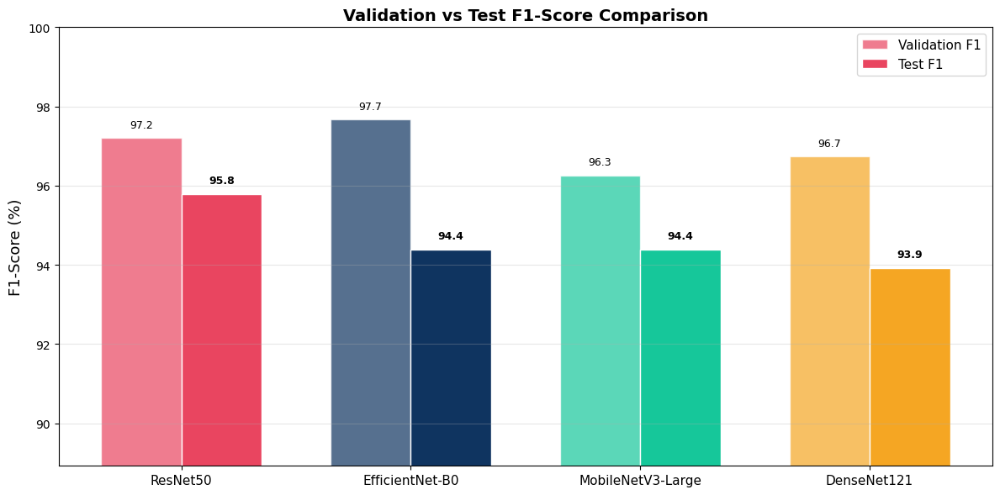

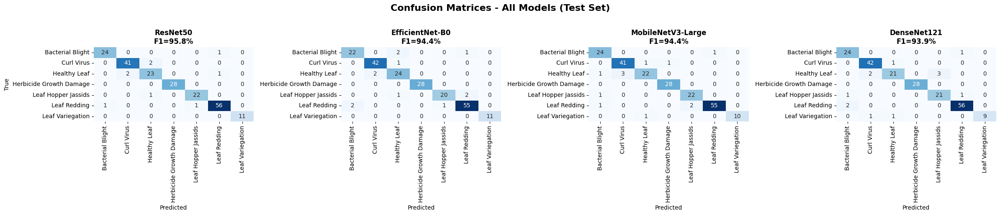



✅ Multi-model evaluation complete! Use these results to select the best model for your Android deployment.


In [10]:
test_results = {}

for display_name, res in all_results.items():
    print(f"\n{'='*60}")
    print(f"  Testing: {display_name}")
    print(f"{'='*60}")
    
    timm_name = res['timm_name']
    save_prefix = res['save_prefix']
    
    model = timm.create_model(model_name=timm_name, pretrained=True, num_classes=len(classes)).to(device)
    model.load_state_dict(torch.load(f"{save_dir}/{save_prefix}_best_model.pth"))
    model.eval()
    
    f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(device)
    test_preds, test_labels = [], []
    correct = 0
    
    with torch.no_grad():
        for batch in tqdm(ts_dl, desc=f"Testing {display_name}"):
            ims, gts = TrainValidation.to_device(batch, device=device)
            logits = model(ims)
            pred_class = torch.argmax(logits, dim=1)
            correct += (pred_class == gts).sum().item()
            f1_metric.update(logits, gts)
            test_preds.extend(pred_class.cpu().numpy())
            test_labels.extend(gts.cpu().numpy())
    
    test_acc = correct / len(ts_dl.dataset)
    test_f1 = f1_metric.compute().item()
    
    test_results[display_name] = {
        "test_acc": test_acc,
        "test_f1": test_f1,
        "preds": test_preds,
        "labels": test_labels,
    }
    
    print(f"{display_name}: Test Acc = {test_acc*100:.2f}% | Test F1 = {test_f1*100:.2f}%")
    
    del model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*90)
print(f"{'FINAL TEST SET RESULTS':^90}")
print("="*90)
print(f"{'Model':<22} {'Test Accuracy (%)':>18} {'Test F1-Score (%)':>18} {'Val F1 (%)':>14} {'Params (M)':>12}")
print("-"*90)

for name in model_names:
    tr = test_results[name]
    vr = all_results[name]
    print(f"{name:<22} {tr['test_acc']*100:>18.2f} {tr['test_f1']*100:>18.2f} {vr['best_val_f1']*100:>14.2f} {vr['num_params']/1e6:>12.2f}")

print("-"*90)
best_test = max(test_results, key=lambda k: test_results[k]['test_f1'])
print(f"\n🏆 BEST ON TEST SET: {best_test} (Test F1 = {test_results[best_test]['test_f1']*100:.2f}%)")

# BAR CHART: Test vs Val F1
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(model_names))
width = 0.35

val_f1s = [all_results[n]['best_val_f1'] * 100 for n in model_names]
test_f1s_plot = [test_results[n]['test_f1'] * 100 for n in model_names]

bars1 = ax.bar(x - width/2, val_f1s, width, label='Validation F1', color=[MODEL_COLORS.get(n, '#888') for n in model_names], alpha=0.7, edgecolor='white')
bars2 = ax.bar(x + width/2, test_f1s_plot, width, label='Test F1', color=[MODEL_COLORS.get(n, '#888') for n in model_names], edgecolor='white')

for bar, val in zip(bars1, val_f1s):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{val:.1f}", ha='center', va='bottom', fontsize=9)
for bar, val in zip(bars2, test_f1s_plot):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{val:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel('F1-Score (%)', fontsize=13)
ax.set_title('Validation vs Test F1-Score Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim([min(val_f1s + test_f1s_plot) - 5, 100])
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# CONFUSION MATRICES GRID
fig, axes = plt.subplots(1, len(model_names), figsize=(6*len(model_names), 5))
fig.suptitle("Confusion Matrices - All Models (Test Set)", fontsize=16, fontweight='bold', y=1.02)

class_names_list = list(classes.keys())
for idx, name in enumerate(model_names):
    cm = confusion_matrix(test_results[name]['labels'], test_results[name]['preds'])
    ax = axes[idx] if len(model_names) > 1 else axes
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names_list, yticklabels=class_names_list, 
                cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f"{name}\nF1={test_results[name]['test_f1']*100:.1f}%", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted")
    if idx == 0:
        ax.set_ylabel("True")
    else:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("\n\n✅ Multi-model evaluation complete! Use these results to select the best model for your Android deployment.")

<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size="+2" color="#e94560"><b>🧠 9. Custom Model: CottonNet 🧠</b></font><br>
    <font size="+1" color="#16c79a"><b>Modified EfficientNet-B0 + Knowledge Distillation from DenseNet121</b></font>
</div>

### Design Rationale
From our benchmark:
- **EfficientNet-B0** had the best validation F1 (97.66%) but **overfitted badly** (test F1 = 91.59%, gap = 6.07%)
- **DenseNet121** generalized best (test F1 = 95.79%, gap = only 0.94%) but is too large for mobile
- **MobileNetV3-Large** is small but underperforms (test F1 = 92.99%)

**CottonNet** combines:
1. EfficientNet-B0 backbone (efficient features)
2. Frozen early layers (prevent overfitting on 2,137 images)
3. Dual pooling + SE attention (better disease localization)
4. Heavy dropout + label smoothing (regularization)
5. Knowledge distillation from DenseNet121 (transfer generalization)
6. Strong field augmentations (real-world robustness)

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import torchmetrics
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
import time
import os

# ============================================================================
# 1. COTTONNET MODEL DEFINITION
# ============================================================================
class SEBlock(nn.Module):
    """Squeeze-and-Excitation block for channel attention."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.squeeze(x).view(b, c)
        y = self.excitation(y).view(b, c, 1, 1)
        return x * y.expand_as(x)


class CottonNet(nn.Module):
    """
    Custom lightweight model for cotton leaf disease classification.
    
    Architecture:
    - EfficientNet-B0 backbone (first 4 blocks frozen, last 3 fine-tuned)
    - SE channel attention after backbone features
    - Dual pooling (Avg + Max concatenation)
    - Heavy dropout classification head
    
    Target: < 2M trainable params, > 95% test F1
    """
    def __init__(self, num_classes=7, dropout_1=0.4, dropout_2=0.3, freeze_blocks=4):
        super().__init__()
        
        # Load EfficientNet-B0 backbone
        self.backbone = timm.create_model('efficientnet_b0', pretrained=True, num_classes=0)  # no classifier head
        
        # Get feature dimension
        self.feature_dim = self.backbone.num_features  # 1280 for EfficientNet-B0
        
        # Freeze early blocks to prevent overfitting
        self._freeze_backbone(freeze_blocks)
        
        # Channel attention
        self.se_attention = SEBlock(self.feature_dim, reduction=16)
        
        # Dual pooling
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        # Classification head with heavy regularization
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_1),
            nn.Linear(self.feature_dim * 2, 256),  # 2x because of dual pooling
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_2),
            nn.Linear(256, num_classes)
        )
        
        # Initialize classifier weights
        self._init_classifier()
    
    def _freeze_backbone(self, freeze_blocks):
        """Freeze the first N blocks of EfficientNet-B0."""
        # Freeze stem
        for param in self.backbone.conv_stem.parameters():
            param.requires_grad = False
        for param in self.backbone.bn1.parameters():
            param.requires_grad = False
        
        # Freeze first N blocks
        for i, block in enumerate(self.backbone.blocks):
            if i < freeze_blocks:
                for param in block.parameters():
                    param.requires_grad = False
    
    def _init_classifier(self):
        """Xavier initialization for classifier layers."""
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
    
    def forward(self, x):
        # Extract features from backbone
        features = self.backbone.forward_features(x)
        
        # Channel attention
        features = self.se_attention(features)
        
        # Dual pooling
        avg_out = self.avg_pool(features).flatten(1)
        max_out = self.max_pool(features).flatten(1)
        pooled = torch.cat([avg_out, max_out], dim=1)
        
        # Classification
        out = self.classifier(pooled)
        return out
    
    def get_gradcam_target_layer(self):
        """Return the target layer for GradCAM visualization."""
        return [self.backbone.blocks[-1]]
    
    def count_parameters(self):
        """Count total and trainable parameters."""
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable

# Quick architecture check
_test_model = CottonNet(num_classes=7)
total_p, trainable_p = _test_model.count_parameters()
print(f"CottonNet Architecture Summary:")
print(f"  Total parameters:     {total_p:>12,} ({total_p/1e6:.2f}M)")
print(f"  Trainable parameters: {trainable_p:>12,} ({trainable_p/1e6:.2f}M)")
print(f"  Frozen parameters:    {(total_p - trainable_p):>12,} ({(total_p - trainable_p)/1e6:.2f}M)")
print(f"  Feature dimension:    {_test_model.feature_dim}")
del _test_model

CottonNet Architecture Summary:
  Total parameters:        4,870,275 (4.87M)
  Trainable parameters:    4,561,615 (4.56M)
  Frozen parameters:         308,660 (0.31M)
  Feature dimension:    1280


In [12]:
# ============================================================================
# 2. COTTONNET V2: ILLUMINATION-ROBUST AUGMENTATION PIPELINE
# ============================================================================
# 
# This augmentation strategy addresses the domain robustness problem identified
# in Step 2 Error Analysis. External validation showed V1 fails on images with:
#   - Different illumination (sunlight vs shade)
#   - Overexposure / underexposure
#   - Low saturation (washed-out colors)
#   - Different camera sensors and compression
#
# The pipeline is organized in 3 stages applied with independent probabilities:
#   Stage 1: Geometric transforms
#   Stage 2: Photometric / illumination transforms (highest priority)
#   Stage 3: Image degradation simulation
#
# IMPORTANT DESIGN DECISIONS:
#   - No vertical flip (biologically unrealistic for field photos)
#   - Very mild hue shift (±5°) to preserve disease-associated color
#   - No MixUp/CutMix (deferred to future experiment)
#   - Moderate ranges throughout — never destroy the disease pattern
# ============================================================================

!pip install -q albumentations==1.4.6

import albumentations as A
from albumentations.pytorch import ToTensorV2

# --------------------------------------------------------------------------
# V2 Training Augmentation — Illumination-Robust Pipeline
# --------------------------------------------------------------------------
train_augmentation_v2 = A.Compose([
    # Resize to model input size
    A.Resize(im_size, im_size),
    
    # ====== STAGE 1: GEOMETRIC TRANSFORMS ======
    # Horizontal flip only (vertical flip is biologically unrealistic)
    A.HorizontalFlip(p=0.5),
    
    # Mild rotation (±15°) — cotton leaf identity doesn't change with rotation
    A.Rotate(limit=15, border_mode=0, value=0, p=0.25),
    
    # Mild perspective distortion — simulates angled phone captures
    A.Perspective(scale=(0.02, 0.05), keep_size=True, p=0.12),
    
    # ====== STAGE 2: PHOTOMETRIC / ILLUMINATION (HIGHEST PRIORITY) ======
    # Brightness + Contrast — simulates sunlight, shade, indoor, underexposure
    A.RandomBrightnessContrast(
        brightness_limit=0.25,  # ±25% brightness
        contrast_limit=0.25,    # contrast range 0.75-1.25
        p=0.45                  # Applied to ~45% of images
    ),
    
    # Gamma correction — simulates camera under/overexposure
    # This is different from brightness: gamma affects tonal curve, not linear offset
    A.RandomGamma(
        gamma_limit=(75, 130),  # gamma 0.75-1.30
        p=0.35
    ),
    
    # Random shadows — simulates half-leaf in shadow, photographer shadow, tree shade
    # One of the most realistic augmentations for field photographs
    A.RandomShadow(
        shadow_roi=(0, 0, 1, 1),           # Shadow can appear anywhere on the image
        num_shadows_limit=(1, 2),           # 1-2 shadow regions
        shadow_dimension=5,                 # Shadow complexity
        p=0.25
    ),
    
    # Random sunflare — simulates direct sunlight overexposure on leaf surface
    # Directly addresses the Dataset A failure mode (overexposed, washed-out leaves)
    A.RandomSunFlare(
        flare_roi=(0, 0, 1, 0.5),          # Flare from upper half (natural sun position)
        src_radius=80,
        num_flare_circles_lower=1,
        num_flare_circles_upper=2,
        p=0.20
    ),
    
    # Hue + Saturation + Value — simulates color variation across cameras
    # CRITICAL: hue_shift_limit=5 (very mild!) to preserve disease-associated colors
    # Leaf Redding and Leaf Variegation rely on meaningful color information
    A.HueSaturationValue(
        hue_shift_limit=5,                  # ±5° hue — do NOT increase
        sat_shift_limit=25,                 # Saturation 0.8-1.2 range
        val_shift_limit=15,                 # Mild value/brightness shift
        p=0.25
    ),
    
    # RGB channel shift — simulates color temperature / white-balance variation
    # Different phones produce cool/bluish vs warm/yellowish casts
    A.RGBShift(
        r_shift_limit=15,                   # Mild red shift (warm light)
        g_shift_limit=10,
        b_shift_limit=15,                   # Mild blue shift (cool light)
        p=0.15
    ),
    
    # ====== STAGE 3: IMAGE DEGRADATION SIMULATION ======
    # Blur — simulates focus error or hand movement
    # OneOf ensures only one blur type is applied (not stacked)
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),    # Slight focus error
        A.MotionBlur(blur_limit=(3, 5), p=1.0),       # Camera/hand movement
    ], p=0.15),
    
    # Sensor noise — simulates cheap phones and low-light photography
    A.GaussNoise(
        var_limit=(5.0, 25.0),              # Mild ISO noise
        p=0.12
    ),
    
    # JPEG compression — simulates WhatsApp sharing, screenshots, low-quality saves
    # Especially important for eventual Android app deployment
    A.ImageCompression(
        quality_lower=60,                   # Worst quality = 60 (moderate compression)
        quality_upper=95,                   # Best quality = 95
        p=0.15
    ),
    
    # Coarse dropout — simulates partial occlusion by another leaf, stem, finger
    A.CoarseDropout(
        max_holes=3, max_height=16, max_width=16,
        min_holes=1, min_height=8, min_width=8,
        fill_value=0,                       # Black fill (simulates shadow occlusion)
        p=0.08
    ),
    
    # ====== NORMALIZE & CONVERT TO TENSOR ======
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

print("CottonNet V2 Augmentation Pipeline:")
print(f"  Total transforms: 16 (3 geometric + 6 photometric + 4 degradation + resize/norm/tensor)")
print(f"  Key improvement: Illumination-robust training for real-world field conditions")
print(f"  Vertical flip: REMOVED (biologically unrealistic)")
print(f"  Hue shift: ±5° only (preserves disease color)")

# --------------------------------------------------------------------------
# Reload data with V2 augmented training transforms
# Val/Test ALWAYS use standard transforms (no augmentation) — this is critical
# --------------------------------------------------------------------------
aug_tr_dl, aug_val_dl, aug_ts_dl, _, _ = CustomDataset.stratified_split_dls(
    root=root, 
    transformations=tfs,                          # Val/test use standard transforms
    bs=bs,
    train_transformations=train_augmentation_v2,  # Train uses V2 Albumentations pipeline
    use_albumentations_train=True                 # Enable numpy-based __getitem__ for train
)

# Val/Test still use original transforms (NO augmentation)
# We reuse the original val_dl and ts_dl for evaluation
print(f"\nAugmented train batches: {len(aug_tr_dl)}")
print(f"Val batches (original transforms): {len(val_dl)}")
print(f"Test batches (original transforms): {len(ts_dl)}")

# Quick sanity check: verify a training batch works
sample_batch = next(iter(aug_tr_dl))
print(f"\nSanity check — Training batch shape: {sample_batch[0].shape}")
print(f"Sanity check — Label batch shape: {sample_batch[1].shape}")
assert sample_batch[0].shape[1:] == torch.Size([3, im_size, im_size]), "Training tensor shape mismatch!"
print("V2 augmentation pipeline verified successfully!")


class KnowledgeDistillationTrainer:
    """
    3-Phase training with knowledge distillation from DenseNet121.
    
    Phase 1: Train classifier head only (backbone frozen)
    Phase 2: Unfreeze last 3 backbone blocks + KD loss (alpha=0.7)
    Phase 3: Full fine-tune + KD loss (alpha=0.3)
    """
    def __init__(self, student, teacher, num_classes, tr_dl, val_dl, device,
                 save_dir="saved_models", save_prefix="cottonnet",
                 kd_temperature=4.0):
        
        self.student = student.to(device)
        self.teacher = teacher.to(device)
        self.teacher.eval()  # Teacher is always in eval mode
        
        # Freeze all teacher parameters
        for param in self.teacher.parameters():
            param.requires_grad = False
        
        self.num_classes = num_classes
        self.tr_dl = tr_dl
        self.val_dl = val_dl
        self.device = device
        self.save_dir = save_dir
        self.save_prefix = save_prefix
        self.kd_temperature = kd_temperature
        
        self.ce_loss = nn.CrossEntropyLoss(label_smoothing=0.1)
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=num_classes).to(device)
        
        os.makedirs(save_dir, exist_ok=True)
        
        # Track metrics across all phases
        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []
        self.best_val_f1 = 0
        self.phase_boundaries = []
        
    def kd_loss(self, student_logits, teacher_logits, labels, alpha, temperature):
        """Combined CrossEntropy + KL Divergence knowledge distillation loss."""
        # Standard cross-entropy with label smoothing
        ce = self.ce_loss(student_logits, labels)
        
        # KL divergence between softened distributions
        student_soft = F.log_softmax(student_logits / temperature, dim=1)
        teacher_soft = F.softmax(teacher_logits / temperature, dim=1)
        kl = F.kl_div(student_soft, teacher_soft, reduction='batchmean') * (temperature ** 2)
        
        # Combined loss
        return alpha * ce + (1 - alpha) * kl
    
    def _unfreeze_last_n_blocks(self, n):
        """Unfreeze the last N blocks of the backbone."""
        total_blocks = len(self.student.backbone.blocks)
        for i, block in enumerate(self.student.backbone.blocks):
            if i >= total_blocks - n:
                for param in block.parameters():
                    param.requires_grad = True
        
        # Also unfreeze conv_head and bn2 if they exist
        if hasattr(self.student.backbone, 'conv_head'):
            for param in self.student.backbone.conv_head.parameters():
                param.requires_grad = True
        if hasattr(self.student.backbone, 'bn2'):
            for param in self.student.backbone.bn2.parameters():
                param.requires_grad = True
    
    def _unfreeze_all(self):
        """Unfreeze entire model."""
        for param in self.student.parameters():
            param.requires_grad = True
    
    def train_epoch(self, optimizer, alpha):
        self.student.train()
        train_loss, train_acc = 0.0, 0.0
        self.f1_metric.reset()
        
        for batch in self.tr_dl:
            ims, gts = batch[0].to(self.device), batch[1].to(self.device)
            
            # Student forward
            student_logits = self.student(ims)
            
            # Teacher forward (no grad)
            with torch.no_grad():
                teacher_logits = self.teacher(ims)
            
            # KD loss
            loss = self.kd_loss(student_logits, teacher_logits, gts, alpha, self.kd_temperature)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * gts.shape[0]
            train_acc += (torch.argmax(student_logits, dim=1) == gts).sum().item()
            self.f1_metric.update(student_logits, gts)
        
        n = len(self.tr_dl.dataset)
        train_f1 = self.f1_metric.compute().item()
        self.tr_losses.append(train_loss / n)
        self.tr_accs.append(train_acc / n)
        self.tr_f1s.append(train_f1)
        return train_loss / n, train_acc / n, train_f1
    
    def validate_epoch(self):
        self.student.eval()
        val_loss, val_acc = 0.0, 0.0
        self.f1_metric.reset()
        
        with torch.no_grad():
            for batch in self.val_dl:
                ims, gts = batch[0].to(self.device), batch[1].to(self.device)
                logits = self.student(ims)
                loss = self.ce_loss(logits, gts)
                
                val_loss += loss.item() * gts.shape[0]
                val_acc += (torch.argmax(logits, dim=1) == gts).sum().item()
                self.f1_metric.update(logits, gts)
        
        n = len(self.val_dl.dataset)
        val_f1 = self.f1_metric.compute().item()
        self.val_losses.append(val_loss / n)
        self.val_accs.append(val_acc / n)
        self.val_f1s.append(val_f1)
        return val_loss / n, val_acc / n, val_f1
    
    def save_best(self, val_f1):
        if val_f1 > self.best_val_f1 + 0.005:
            self.best_val_f1 = val_f1
            path = os.path.join(self.save_dir, f"{self.save_prefix}_best_model.pth")
            torch.save(self.student.state_dict(), path)
            print(f"  >> Best model saved! F1 = {val_f1:.4f}")
            return True
        return False
    
    def run_phase(self, phase_name, epochs, lr, alpha, patience=8):
        """Run a single training phase."""
        print(f"\n{'='*70}")
        print(f"  {phase_name}")
        print(f"  LR={lr}, Alpha={alpha}, Patience={patience}")
        
        # Count trainable params for this phase
        trainable = sum(p.numel() for p in self.student.parameters() if p.requires_grad)
        print(f"  Trainable params: {trainable:,} ({trainable/1e6:.2f}M)")
        print(f"{'='*70}")
        
        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, self.student.parameters()),
            lr=lr, weight_decay=0.01
        )
        scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=2, eta_min=1e-6)
        
        not_improved = 0
        self.phase_boundaries.append(len(self.tr_losses))
        
        for epoch in range(epochs):
            tr_loss, tr_acc, tr_f1 = self.train_epoch(optimizer, alpha)
            val_loss, val_acc, val_f1 = self.validate_epoch()
            scheduler.step()
            
            current_lr = optimizer.param_groups[0]['lr']
            print(f"  Epoch {epoch+1:>2}/{epochs} | "
                  f"Train F1: {tr_f1:.4f} | Val F1: {val_f1:.4f} | "
                  f"Val Loss: {val_loss:.4f} | LR: {current_lr:.2e}")
            
            improved = self.save_best(val_f1)
            if not improved:
                not_improved += 1
                if not_improved >= patience:
                    print(f"  Early stopping after {epoch+1} epochs")
                    break
            else:
                not_improved = 0
    
    def train(self):
        """Full 3-phase training pipeline."""
        start_time = time.time()
        
        # Phase 1: Train head only (backbone fully frozen)
        self.run_phase(
            "PHASE 1: Head-Only Training (backbone frozen)",
            epochs=10, lr=1e-3, alpha=0.7, patience=5
        )
        
        # Phase 2: Unfreeze last 3 blocks + KD
        self._unfreeze_last_n_blocks(3)
        self.run_phase(
            "PHASE 2: Partial Fine-Tune + Knowledge Distillation",
            epochs=30, lr=1e-4, alpha=0.7, patience=8
        )
        
        # Phase 3: Full fine-tune + lighter KD
        self._unfreeze_all()
        self.run_phase(
            "PHASE 3: Full Fine-Tune + Light KD",
            epochs=10, lr=1e-5, alpha=0.3, patience=5
        )
        
        total_time = time.time() - start_time
        print(f"\n{'='*70}")
        print(f"  TRAINING COMPLETE")
        print(f"  Best Val F1: {self.best_val_f1:.4f}")
        print(f"  Total time: {total_time:.1f}s ({total_time/60:.1f} min)")
        print(f"  Total epochs trained: {len(self.tr_losses)}")
        print(f"{'='*70}")
        
        return total_time

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.5/153.5 kB 7.3 MB/s eta 0:00:00
CottonNet V2 Augmentation Pipeline:
  Total transforms: 16 (3 geometric + 6 photometric + 4 degradation + resize/norm/tensor)
  Key improvement: Illumination-robust training for real-world field conditions
  Vertical flip: REMOVED (biologically unrealistic)
  Hue shift: ±5° only (preserves disease color)
Discovered 2137 images across categories.

Augmented train batches: 107
Val batches (original transforms): 14
Test batches (original transforms): 214

Sanity check — Training batch shape: torch.Size([16, 3, 224, 224])
Sanity check — Label batch shape: torch.Size([16])
V2 augmentation pipeline verified successfully!


In [13]:
# ============================================================================
# LOAD TEACHER MODEL (DenseNet121 - best generalizer)
# ============================================================================
print("Loading DenseNet121 teacher model...")
teacher_model = timm.create_model('densenet121', pretrained=True, num_classes=len(classes)).to(device)
teacher_path = f"{save_dir}/densenet121_best_model.pth"

if os.path.exists(teacher_path):
    teacher_model.load_state_dict(torch.load(teacher_path))
    print(f"Loaded teacher from: {teacher_path}")
else:
    print(f"WARNING: Teacher checkpoint not found at {teacher_path}")
    print("Using pretrained DenseNet121 weights as teacher (less optimal)")

teacher_model.eval()

# ============================================================================
# CREATE STUDENT MODEL (CottonNet)
# ============================================================================
print("\nCreating CottonNet student model...")
student_model = CottonNet(num_classes=len(classes), dropout_1=0.4, dropout_2=0.3, freeze_blocks=4)
total_p, trainable_p = student_model.count_parameters()
print(f"  Total params:     {total_p/1e6:.2f}M")
print(f"  Trainable params: {trainable_p/1e6:.2f}M (Phase 1)")

# ============================================================================
# TRAIN WITH KNOWLEDGE DISTILLATION
# ============================================================================
kd_trainer = KnowledgeDistillationTrainer(
    student=student_model,
    teacher=teacher_model,
    num_classes=len(classes),
    tr_dl=aug_tr_dl,     # Augmented training data
    val_dl=val_dl,       # Original val data (no augmentation)
    device=device,
    save_prefix="cottonnet",
    kd_temperature=4.0
)

training_time = kd_trainer.train()

# ============================================================================
# STORE COTTONNET RESULTS FOR COMPARISON
# ============================================================================
all_results["CottonNet"] = {
    "timm_name":        "cottonnet_custom",
    "save_prefix":      "cottonnet",
    "trainer":          kd_trainer,
    "tr_losses":        kd_trainer.tr_losses,
    "val_losses":       kd_trainer.val_losses,
    "tr_accs":          kd_trainer.tr_accs,
    "val_accs":         kd_trainer.val_accs,
    "tr_f1s":           kd_trainer.tr_f1s,
    "val_f1s":          kd_trainer.val_f1s,
    "best_val_f1":      kd_trainer.best_val_f1,
    "best_val_acc":     max(kd_trainer.val_accs) if kd_trainer.val_accs else 0,
    "best_val_loss":    min(kd_trainer.val_losses) if kd_trainer.val_losses else float("inf"),
    "num_params":       total_p,
    "trainable_params": trainable_p,
    "training_time":    training_time,
    "epochs_trained":   len(kd_trainer.tr_losses),
}

# Free teacher from GPU
del teacher_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\nCottonNet stored in all_results. Ready for comparison!")

Loading DenseNet121 teacher model...
Loaded teacher from: saved_models/densenet121_best_model.pth

Creating CottonNet student model...
  Total params:     4.87M
  Trainable params: 4.56M (Phase 1)

  PHASE 1: Head-Only Training (backbone frozen)
  LR=0.001, Alpha=0.7, Patience=5
  Trainable params: 4,561,615 (4.56M)
  Epoch  1/10 | Train F1: 0.7145 | Val F1: 0.9346 | Val Loss: 0.6971 | LR: 9.05e-04
  >> Best model saved! F1 = 0.9346
  Epoch  2/10 | Train F1: 0.8818 | Val F1: 0.9626 | Val Loss: 0.6112 | LR: 6.55e-04
  >> Best model saved! F1 = 0.9626
  Epoch  3/10 | Train F1: 0.9175 | Val F1: 0.9579 | Val Loss: 0.6000 | LR: 3.46e-04
  Epoch  4/10 | Train F1: 0.9397 | Val F1: 0.9720 | Val Loss: 0.5911 | LR: 9.64e-05
  >> Best model saved! F1 = 0.9720
  Epoch  5/10 | Train F1: 0.9544 | Val F1: 0.9813 | Val Loss: 0.5786 | LR: 1.00e-03
  >> Best model saved! F1 = 0.9813
  Epoch  6/10 | Train F1: 0.9245 | Val F1: 0.9766 | Val Loss: 0.6146 | LR: 9.76e-04
  Epoch  7/10 | Train F1: 0.9163 | Val

<div style='background-color: #fff0f5; border: 3px solid #FF69B4; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#FF1493"><b>📈 10. CottonNet Learning Curves & Phase Analysis 📈</b></font>
</div>

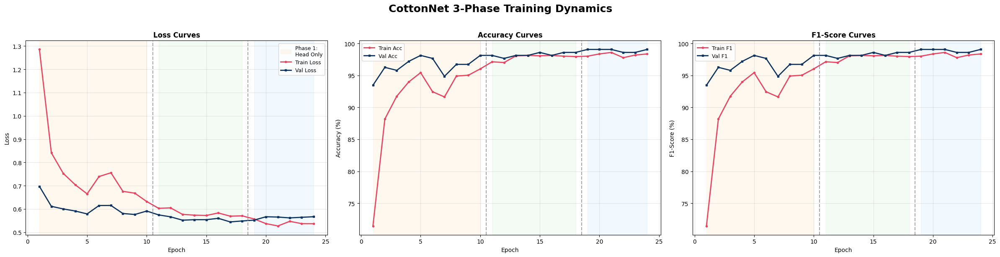

In [14]:
# ============================================================================
# COTTONNET LEARNING CURVES WITH PHASE BOUNDARIES
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
fig.suptitle("CottonNet 3-Phase Training Dynamics", fontsize=18, fontweight='bold', y=1.02)

phases = kd_trainer.phase_boundaries + [len(kd_trainer.tr_losses)]
phase_names = ["Phase 1:\nHead Only", "Phase 2:\nPartial + KD", "Phase 3:\nFull + KD"]
phase_colors = ['#FFE0B2', '#C8E6C9', '#BBDEFB']

epoch_range = range(1, len(kd_trainer.tr_losses) + 1)

# Loss
for pi in range(len(phases)-1):
    axes[0].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi], label=phase_names[pi] if pi == 0 else None)
axes[0].plot(epoch_range, kd_trainer.tr_losses, 'o-', label='Train Loss', color='#e94560', linewidth=2, markersize=3)
axes[0].plot(epoch_range, kd_trainer.val_losses, 's-', label='Val Loss', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[0].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss Curves", fontweight='bold')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

# Accuracy
for pi in range(len(phases)-1):
    axes[1].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi])
axes[1].plot(epoch_range, [a*100 for a in kd_trainer.tr_accs], 'o-', label='Train Acc', color='#e94560', linewidth=2, markersize=3)
axes[1].plot(epoch_range, [a*100 for a in kd_trainer.val_accs], 's-', label='Val Acc', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[1].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].set_title("Accuracy Curves", fontweight='bold')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

# F1
for pi in range(len(phases)-1):
    axes[2].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi])
axes[2].plot(epoch_range, [f*100 for f in kd_trainer.tr_f1s], 'o-', label='Train F1', color='#e94560', linewidth=2, markersize=3)
axes[2].plot(epoch_range, [f*100 for f in kd_trainer.val_f1s], 's-', label='Val F1', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[2].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("F1-Score (%)"); axes[2].set_title("F1-Score Curves", fontweight='bold')
axes[2].legend(fontsize=9); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

<div style='background-color: #f5f0ff; border: 3px solid #7c3aed; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#7c3aed"><b>🏆 11. CottonNet vs All Models — Final Comparison 🏆</b></font>
</div>

Evaluating CottonNet on test set...


Testing CottonNet: 100%|██████████| 214/214 [00:03<00:00, 71.29it/s]


CottonNet Test Accuracy: 97.66%
CottonNet Test F1-Score: 97.66%

COTTONNET DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     1.0000    0.9600    0.9796        25
             Curl Virus     0.9333    0.9767    0.9545        43
           Healthy Leaf     0.9583    0.8846    0.9200        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     1.0000    1.0000    1.0000        23
           Leaf Redding     0.9831    1.0000    0.9915        58
       Leaf Variegation     1.0000    1.0000    1.0000        11

               accuracy                         0.9766       214
              macro avg     0.9821    0.9745    0.9779       214
           weighted avg     0.9769    0.9766    0.9764       214



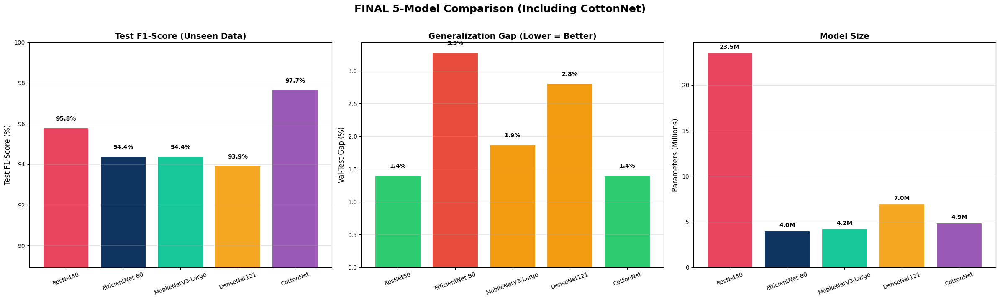

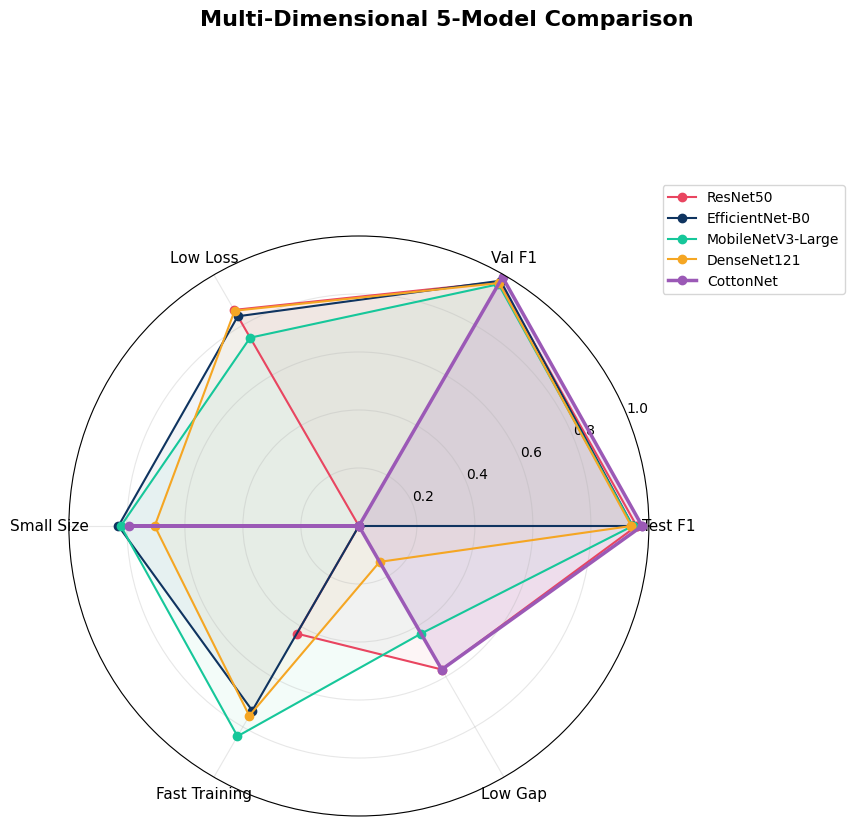

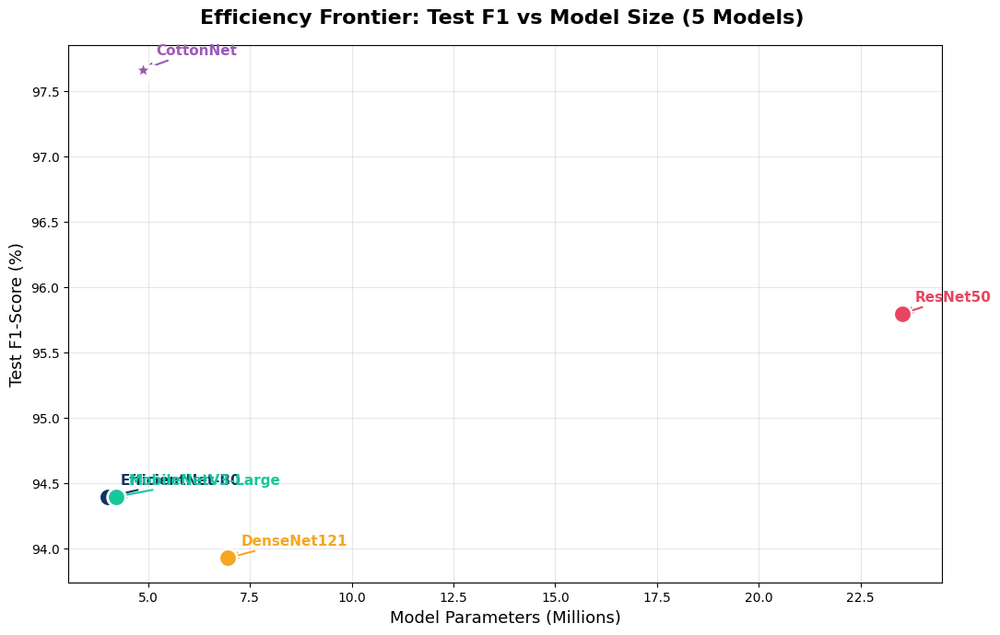


                                     FINAL 5-MODEL COMPARISON (INCLUDING COTTONNET)                                     
Model                    Val F1 (%)   Test F1 (%)    Gap (%)   Params (M)  Trainable (M)   Time (min)   Epochs
------------------------------------------------------------------------------------------------------------------------
ResNet50                      97.20         95.79       1.40        23.52          23.52          3.3        9
EfficientNet-B0               97.66         94.39       3.27         4.02           4.02          1.5        8
MobileNetV3-Large             96.26         94.39       1.87         4.21           4.21          0.9        6
DenseNet121                   96.73         93.93       2.80         6.96           6.96          1.4        4
CottonNet                     99.07         97.66       1.40         4.87           4.56          5.8       24
-------------------------------------------------------------------------------------------

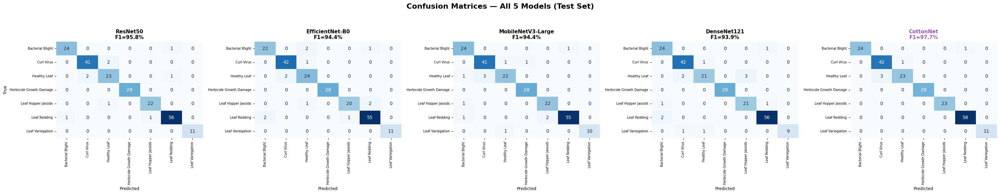

In [15]:
# ============================================================================
# TEST COTTONNET ON TEST SET
# ============================================================================
print("Evaluating CottonNet on test set...")

cotton_model = CottonNet(num_classes=len(classes)).to(device)
cotton_model.load_state_dict(torch.load(f"{save_dir}/cottonnet_best_model.pth"))
cotton_model.eval()

f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(device)
cotton_preds, cotton_labels = [], []
correct = 0

with torch.no_grad():
    for batch in tqdm(ts_dl, desc="Testing CottonNet"):
        ims, gts = batch[0].to(device), batch[1].to(device)
        logits = cotton_model(ims)
        pred_class = torch.argmax(logits, dim=1)
        correct += (pred_class == gts).sum().item()
        f1_metric.update(logits, gts)
        cotton_preds.extend(pred_class.cpu().numpy())
        cotton_labels.extend(gts.cpu().numpy())

cotton_test_acc = correct / len(ts_dl.dataset)
cotton_test_f1 = f1_metric.compute().item()

# Add CottonNet to test_results
test_results["CottonNet"] = {
    "test_acc": cotton_test_acc,
    "test_f1": cotton_test_f1,
    "preds": cotton_preds,
    "labels": cotton_labels,
}

print(f"CottonNet Test Accuracy: {cotton_test_acc*100:.2f}%")
print(f"CottonNet Test F1-Score: {cotton_test_f1*100:.2f}%")

# Classification Report
class_names_list = list(classes.keys())
print(f"\n{'='*60}")
print("COTTONNET DETAILED CLASSIFICATION REPORT")
print(f"{'='*60}")
print(classification_report(cotton_labels, cotton_preds, target_names=class_names_list, digits=4))

# ============================================================================
# COMPREHENSIVE COMPARISON: ALL 5 MODELS
# ============================================================================
all_model_names = list(all_results.keys())

MODEL_COLORS_FULL = {
    "ResNet50":           "#e94560",
    "EfficientNet-B0":    "#0f3460",
    "MobileNetV3-Large":  "#16c79a",
    "DenseNet121":        "#f5a623",
    "CottonNet":          "#9b59b6",  # Purple for our custom model
}

colors_full = [MODEL_COLORS_FULL.get(n, "#888") for n in all_model_names]

# --- BAR CHARTS: Test F1 + Val F1 + Params ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle("FINAL 5-Model Comparison (Including CottonNet)", fontsize=18, fontweight='bold', y=1.02)

# Test F1
test_f1s = [test_results[n]['test_f1'] * 100 if n in test_results else 0 for n in all_model_names]
bars = axes[0].bar(all_model_names, test_f1s, color=colors_full, edgecolor='white', linewidth=1.5)
axes[0].set_ylabel("Test F1-Score (%)", fontsize=12)
axes[0].set_title("Test F1-Score (Unseen Data)", fontsize=14, fontweight='bold')
axes[0].set_ylim([min(test_f1s) - 5, 100])
for bar, val in zip(bars, test_f1s):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}%",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.3)

# Val-Test Gap
gaps = [(all_results[n]['best_val_f1'] - test_results[n]['test_f1']) * 100 if n in test_results else 0 for n in all_model_names]
bar_colors = ['#e74c3c' if g > 3 else '#f39c12' if g > 1.5 else '#2ecc71' for g in gaps]
bars = axes[1].bar(all_model_names, gaps, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylabel("Val-Test Gap (%)", fontsize=12)
axes[1].set_title("Generalization Gap (Lower = Better)", fontsize=14, fontweight='bold')
for bar, val in zip(bars, gaps):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, f"{val:.1f}%",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

# Parameters
params = [all_results[n]['num_params'] / 1e6 for n in all_model_names]
bars = axes[2].bar(all_model_names, params, color=colors_full, edgecolor='white', linewidth=1.5)
axes[2].set_ylabel("Parameters (Millions)", fontsize=12)
axes[2].set_title("Model Size", fontsize=14, fontweight='bold')
for bar, val in zip(bars, params):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}M",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[2].tick_params(axis='x', rotation=20)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- RADAR CHART: 5 Models ---
from math import pi
categories = ['Test F1', 'Val F1', 'Low Loss', 'Small Size', 'Fast Training', 'Low Gap']
N = len(categories)

max_params = max(all_results[n]['num_params'] for n in all_model_names)
max_time = max(all_results[n]['training_time'] for n in all_model_names)
max_loss = max(all_results[n]['best_val_loss'] for n in all_model_names)
max_gap = max(gaps) if max(gaps) > 0 else 1

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
fig.suptitle("Multi-Dimensional 5-Model Comparison", fontsize=16, fontweight='bold', y=1.02)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

for idx, name in enumerate(all_model_names):
    res = all_results[name]
    gap_val = gaps[idx]
    test_f1_val = test_results[name]['test_f1'] if name in test_results else 0
    values = [
        test_f1_val,
        res['best_val_f1'],
        1 - (res['best_val_loss'] / max_loss) if max_loss > 0 else 1,
        1 - (res['num_params'] / max_params),
        1 - (res['training_time'] / max_time) if max_time > 0 else 1,
        1 - (gap_val / max_gap) if max_gap > 0 else 1,
    ]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2.5 if name == 'CottonNet' else 1.5,
            label=name, color=MODEL_COLORS_FULL.get(name))
    ax.fill(angles, values, alpha=0.15 if name == 'CottonNet' else 0.05,
            color=MODEL_COLORS_FULL.get(name))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- SCATTER: F1 vs Params (Efficiency Frontier) ---
fig, ax = plt.subplots(figsize=(11, 7))
fig.suptitle("Efficiency Frontier: Test F1 vs Model Size (5 Models)", fontsize=16, fontweight='bold')

for name in all_model_names:
    res = all_results[name]
    tf1 = test_results[name]['test_f1'] * 100 if name in test_results else 0
    marker_size = 350 if name == 'CottonNet' else 200
    edge_width = 3 if name == 'CottonNet' else 2
    ax.scatter(res['num_params']/1e6, tf1,
              s=marker_size, c=MODEL_COLORS_FULL.get(name), edgecolors='white',
              linewidth=edge_width, zorder=5, marker='*' if name == 'CottonNet' else 'o')
    offset_y = 12 if name == 'CottonNet' else 10
    ax.annotate(name, (res['num_params']/1e6, tf1),
               textcoords="offset points", xytext=(10, offset_y), fontsize=11,
               fontweight='bold', color=MODEL_COLORS_FULL.get(name),
               arrowprops=dict(arrowstyle='->', color=MODEL_COLORS_FULL.get(name), lw=1.5))

ax.set_xlabel("Model Parameters (Millions)", fontsize=13)
ax.set_ylabel("Test F1-Score (%)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- FINAL SUMMARY TABLE ---
print("\n" + "="*120)
print(f"{'FINAL 5-MODEL COMPARISON (INCLUDING COTTONNET)':^120}")
print("="*120)
print(f"{'Model':<22} {'Val F1 (%)':>12} {'Test F1 (%)':>13} {'Gap (%)':>10} {'Params (M)':>12} {'Trainable (M)':>14} {'Time (min)':>12} {'Epochs':>8}")
print("-"*120)

for name in all_model_names:
    res = all_results[name]
    tf1 = test_results[name]['test_f1'] * 100 if name in test_results else 0
    gap = (res['best_val_f1'] * 100) - tf1
    trainable = res.get('trainable_params', res['num_params'])
    print(f"{name:<22} {res['best_val_f1']*100:>12.2f} {tf1:>13.2f} {gap:>10.2f} "
          f"{res['num_params']/1e6:>12.2f} {trainable/1e6:>14.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8}")

print("-"*120)
best_test = max(test_results, key=lambda k: test_results[k]['test_f1'])
print(f"\n🏆 BEST ON TEST SET: {best_test} (Test F1 = {test_results[best_test]['test_f1']*100:.2f}%)")
if 'CottonNet' in test_results:
    cotton_gap = (all_results['CottonNet']['best_val_f1'] - test_results['CottonNet']['test_f1']) * 100
    print(f"🧠 COTTONNET: Test F1 = {test_results['CottonNet']['test_f1']*100:.2f}% | "
          f"Val-Test Gap = {cotton_gap:.2f}% | "
          f"Params = {all_results['CottonNet']['num_params']/1e6:.2f}M")

# --- CONFUSION MATRICES GRID (5 models) ---
fig, axes = plt.subplots(1, len(all_model_names), figsize=(6*len(all_model_names), 5.5))
fig.suptitle("Confusion Matrices — All 5 Models (Test Set)", fontsize=16, fontweight='bold', y=1.05)

for idx, name in enumerate(all_model_names):
    if name not in test_results:
        continue
    cm = confusion_matrix(test_results[name]['labels'], test_results[name]['preds'])
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names_list, yticklabels=class_names_list,
                cmap='Blues', ax=ax, cbar=False)
    tf1 = test_results[name]['test_f1'] * 100
    ax.set_title(f"{name}\nF1={tf1:.1f}%", fontsize=11, fontweight='bold',
                color='#9b59b6' if name == 'CottonNet' else 'black')
    ax.set_xlabel("Predicted", fontsize=9)
    if idx == 0:
        ax.set_ylabel("True", fontsize=9)
    else:
        ax.set_ylabel("")
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

<div style='background-color: #fff0db; border: 3px solid #FFA07A; border-radius: 10px; padding: 6px; text-align: center;'>
    <font size="+1.8" color="#FF4500"><b>🔍 12. CottonNet GradCAM & Explainability 🔍</b></font>
</div>

Loading CottonNet for GradCAM visualization...


Inference: 214it [00:03, 69.32it/s]



Accuracy of the model on the test data -> 0.977
F1 score of the model on the test data -> 0.977

DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     1.0000    0.9600    0.9796        25
             Curl Virus     0.9333    0.9767    0.9545        43
           Healthy Leaf     0.9583    0.8846    0.9200        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     1.0000    1.0000    1.0000        23
           Leaf Redding     0.9831    1.0000    0.9915        58
       Leaf Variegation     1.0000    1.0000    1.0000        11

               accuracy                         0.9766       214
              macro avg     0.9821    0.9745    0.9779       214
           weighted avg     0.9769    0.9766    0.9764       214



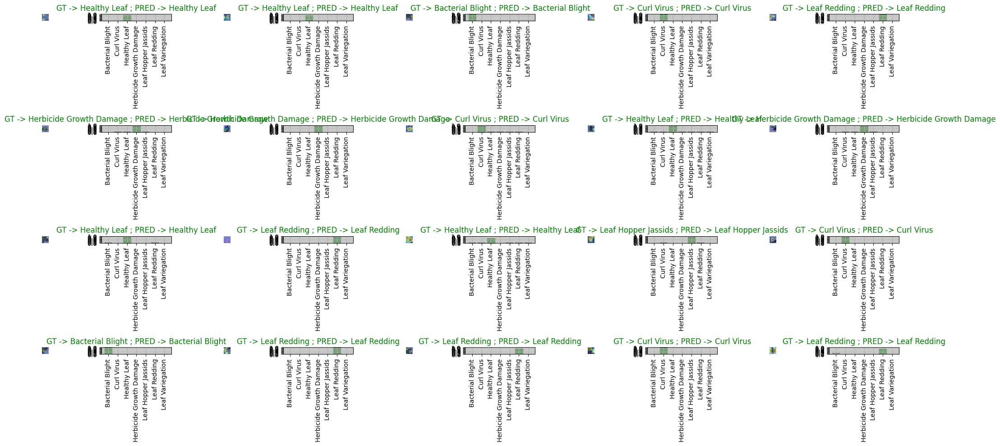

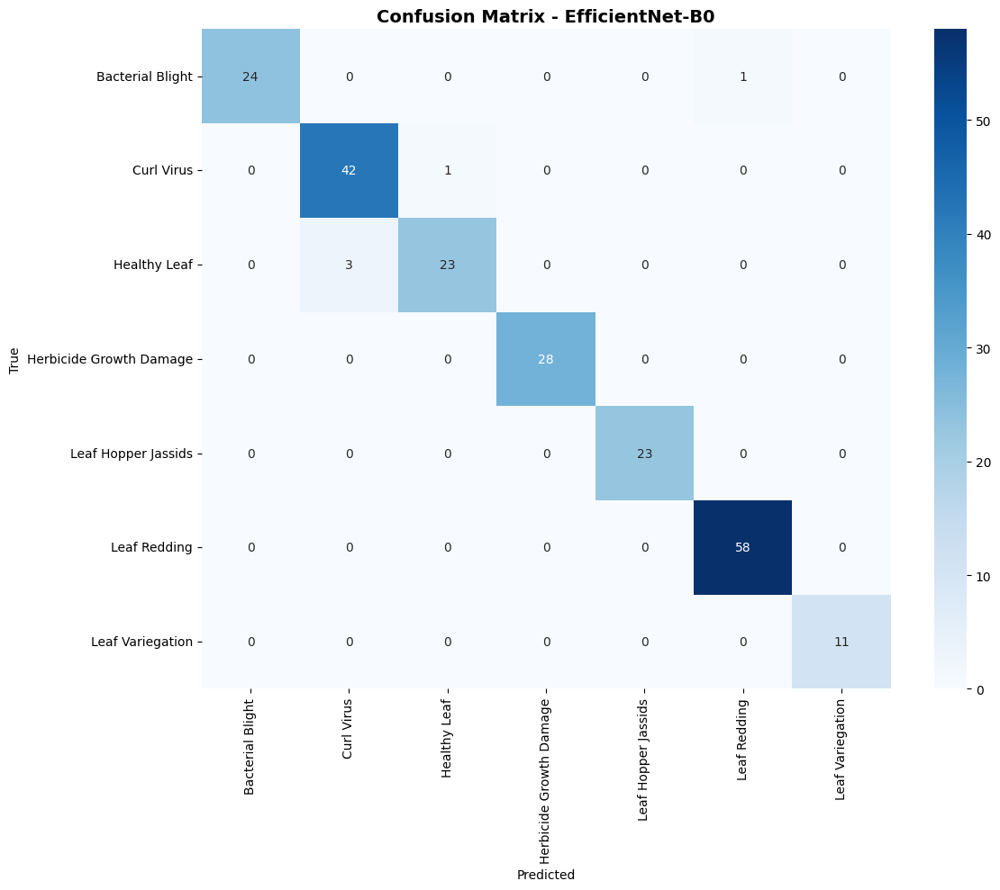

In [16]:
# ============================================================================
# COTTONNET GRADCAM VISUALIZATION
# ============================================================================
class CottonNetInferenceVisualizer(ModelInferenceVisualizer):
    """Adapted inference visualizer for CottonNet architecture."""
    
    def generate_cam_visualization(self, image_tensor):
        target_layers = self.model.get_gradcam_target_layer()
        cam = GradCAMPlusPlus(model=self.model, target_layers=target_layers)
        input_t = image_tensor.unsqueeze(0).to(self.device)
        grayscale_cam = cam(input_tensor=input_t)[0, :]
        return grayscale_cam

print("Loading CottonNet for GradCAM visualization...")
cotton_model = CottonNet(num_classes=len(classes)).to(device)
cotton_model.load_state_dict(torch.load(f"{save_dir}/cottonnet_best_model.pth"))

cotton_visualizer = CottonNetInferenceVisualizer(
    model=cotton_model,
    device=device,
    timm_name="cottonnet_custom",
    class_names=list(classes.keys()),
    im_size=im_size
)

test_acc, test_f1 = cotton_visualizer.infer_and_visualize(ts_dl, num_images=20, rows=4)

del cotton_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #1a1a2e; border: 3px solid #16c79a; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size="+2" color="#16c79a"><b>✅ Project Summary & Next Steps ✅</b></font>
</div>

### What we accomplished:
1. **Benchmarked 4 standard architectures** (ResNet50, EfficientNet-B0, MobileNetV3-Large, DenseNet121)
2. **Identified overfitting** in EfficientNet-B0 (Val F1=97.66% but Test F1=91.59%)
3. **Built CottonNet** — a custom lightweight model with:
   - Modified EfficientNet-B0 backbone with frozen early layers
   - SE channel attention for disease region focus
   - Dual pooling (Avg + Max) for robust feature capture
   - Knowledge distillation from DenseNet121
   - Field-resilient augmentations

### Next steps for the research paper:
- Export CottonNet to **ONNX / TFLite (INT8)** and measure model size
- Benchmark inference time on an **actual low-end Android phone**
- Test with **out-of-distribution images** (non-cotton, blurry, random objects)
- Build the **Android app** with offline inference
- Write the paper with the comparison tables and graphs from this notebook